# BlackSpot Miner: Mining Road Collision Data to Locate Severe-Crash Hotspots and Prioritise Road Safety Action

**DMBI CA2 Mini Project, Division D15A, Group 09**

Jaiprakash Talreja (54), Adarsh Singh (52), Vidushi Singh (53), Piyush Shukla (49)

**Business goal.** A road authority has a limited safety budget. It needs to know where severe crashes concentrate, which conditions make a crash severe, and which sites to treat first.

**Pipeline.** Problem → Data → Preprocessing → Algorithm → Results → Evaluation → Insights → Decision

| Stage | Syllabus link | What this notebook does |
|---|---|---|
| Preprocessing | Module II | Audit fields by year, handle reporting change, clean, encode |
| Hotspot discovery | Module IV | DBSCAN on killed-or-seriously-injured (KSI) collisions |
| Pattern mining | Module V | Apriori rules, K-Modes segmentation as in the reference paper |
| Severity model | Module III | Naive Bayes, Decision Tree, Random Forest, AdaBoost |
| Location model | Module III | Which 500 m cells will record KSI collisions next year |
| Decision | Module VI | Ranked site shortlist with a suggested review type |

**Reference paper.** Kumar, S. and Toshniwal, D. (2015), *A data mining framework to analyze road accident data*, Journal of Big Data 2:26. https://doi.org/10.1186/s40537-015-0035-y

**Data.** Department for Transport, Road Safety Open Data (STATS19), latest 5 years, Open Government Licence v3.0. https://www.gov.uk/government/statistical-data-sets/road-safety-open-data

In [1]:
from pathlib import Path
import json
import time
import urllib.request
import warnings

import folium
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from kmodes.kmodes import KModes
from matplotlib.colors import LinearSegmentedColormap
from mlxtend.frequent_patterns import apriori, association_rules
from scipy.stats import chi2_contingency
from sklearn.calibration import calibration_curve
from sklearn.cluster import DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)
T0 = time.time()

ROOT = Path.cwd()
DATA, FIG, RES = ROOT / "data", ROOT / "figures", ROOT / "results"
for folder in (DATA, FIG, RES):
    folder.mkdir(exist_ok=True)

# every figure quoted in the report and slides is read back from this dictionary
M = {"versions": {"pandas": pd.__version__, "scikit_learn": sklearn.__version__}}

BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

mpl.rcParams.update({
    "figure.dpi": 80, "savefig.dpi": 200, "font.family": "Segoe UI", "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": False, "grid.color": GRID, "grid.linewidth": .7,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()


def hbar(series, title, xlabel, ref=None, ref_label=None, highlight=(), fmt="{:.1f}"):
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(7.2, .36 * len(s) + 1.3))
    colors = [ORANGE if k in highlight else BLUE for k in s.index]
    ax.barh(s.index.astype(str), s.values, color=colors, height=.7, edgecolor=SURFACE, linewidth=1.5)
    for y, v in enumerate(s.values):
        ax.text(v, y, "  " + fmt.format(v), va="center", color=INK2, fontsize=9)
    if ref is not None:
        ax.axvline(ref, color=INK2, linewidth=1)
        ax.text(ref, len(s) - .35, f" {ref_label}", color=INK2, fontsize=8.5, va="bottom")
    ax.set_title(title, pad=20)
    ax.set_xlabel(xlabel)
    ax.margins(x=.12)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    return fig


print("setup done")

setup done


## 1. Data understanding

Three linked tables are used: one row per collision, one per vehicle, one per casualty. They join on `collision_index`.

In [2]:
BASE = "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-"
URLS = {
    "collision.csv": BASE + "collision-last-5-years.csv",
    "vehicle.csv": BASE + "vehicle-last-5-years.csv",
    "casualty.csv": BASE + "casualty-last-5-years.csv",
    "data_guide.xlsx": "https://assets.publishing.service.gov.uk/media/6ab2a71d997a4b2950cced58/"
                       "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx",
}
for name, url in URLS.items():
    if not (DATA / name).exists():
        print("downloading", name)
        urllib.request.urlretrieve(url, DATA / name)

col = pd.read_csv(DATA / "collision.csv", low_memory=False)
veh = pd.read_csv(DATA / "vehicle.csv", usecols=["collision_index", "vehicle_type", "age_of_driver", "vehicle_leaving_carriageway",
                                                 "skidding_and_overturning", "hit_object_off_carriageway", "hit_object_in_carriageway"], low_memory=False)
cas = pd.read_csv(DATA / "casualty.csv", usecols=["collision_index", "casualty_class", "casualty_severity"], low_memory=False)
guide = pd.read_excel(DATA / "data_guide.xlsx", sheet_name="2024_code_list")

M["data"] = {
    "collisions": len(col), "vehicles": len(veh), "casualties": len(cas), "collision_columns": col.shape[1],
    "years": sorted(int(y) for y in col["collision_year"].unique()),
    "killed": int((cas["casualty_severity"] == 1).sum()), "seriously_injured": int((cas["casualty_severity"] == 2).sum()),
}
print(M["data"])
col[["collision_index", "date", "time", "latitude", "longitude", "collision_severity", "speed_limit", "light_conditions"]].head()

{'collisions': 513801, 'vehicles': 937265, 'casualties': 652821, 'collision_columns': 44, 'years': [2021, 2022, 2023, 2024, 2025], 'killed': 8033, 'seriously_injured': 129011}


,collision_index,date,time,latitude,longitude,collision_severity,speed_limit,light_conditions
0,202417H105824,03/10/2024,16:06,54.69840,-1.24700,2,30,1
1,202517M115025,29/11/2025,16:34,54.56387,-1.19147,2,30,4
2,202517L306225,01/06/2025,22:07,54.60600,-1.08390,3,30,4
3,202417S104724,20/04/2024,14:40,54.55157,-1.37599,3,60,1
4,202517S106525,16/05/2025,07:25,54.56228,-1.31596,2,30,1


### 1.1 Field audit, year by year

Fields were redefined in the 2024 STATS19 specification, so each one is checked per year before it is trusted. A model fed a field that changes coding between years learns the coding change, not road risk.

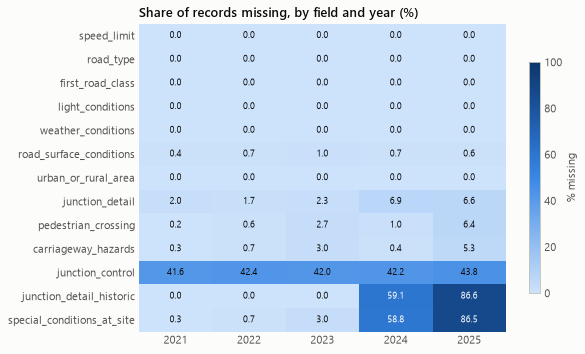

{'special_conditions_missing_2025': 86.5, 'junction_historic_missing_2025': 86.6, 'junction_control_missing_2021': 41.6}


In [3]:
audit_cols = ["speed_limit", "road_type", "first_road_class", "light_conditions", "weather_conditions",
              "road_surface_conditions", "urban_or_rural_area", "junction_detail", "pedestrian_crossing",
              "carriageway_hazards", "junction_control", "junction_detail_historic", "special_conditions_at_site"]
missing = pd.DataFrame({c: ((col[c] == -1) | col[c].isna()).groupby(col["collision_year"]).mean() for c in audit_cols}).T * 100

fig, ax = plt.subplots(figsize=(7.4, 5))
im = ax.imshow(missing.values, cmap=BLUES, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(missing.shape[1]), missing.columns)
ax.set_yticks(range(len(missing)), missing.index)
for i in range(missing.shape[0]):
    for j in range(missing.shape[1]):
        v = missing.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8.5, color="white" if v > 45 else INK)
ax.set_title("Share of records missing, by field and year (%)")
ax.spines[["left", "bottom"]].set_visible(False)
fig.colorbar(im, ax=ax, shrink=.75, label="% missing")
save(fig, "fig01_field_audit")

M["audit"] = {
    "special_conditions_missing_2025": round(float(missing.loc["special_conditions_at_site", 2025]), 1),
    "junction_historic_missing_2025": round(float(missing.loc["junction_detail_historic", 2025]), 1),
    "junction_control_missing_2021": round(float(missing.loc["junction_control", 2021]), 1),
}
print(M["audit"])

### 1.2 The reporting change

Police forces have been moving to injury-based reporting (CRASH and COPA). Officers record the injury and the severity is derived from it, which classifies more casualties as serious than an officer's judgement did. DfT publishes a probability per collision that restates it as if every force used the injury-based system. Raw severity is therefore not comparable across years or forces.

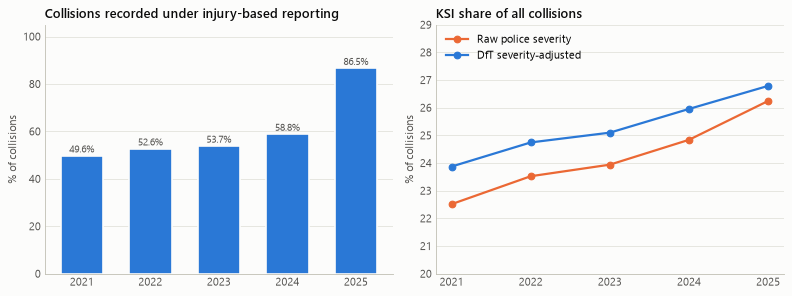

,collisions,ksi_raw,ksi_adj,fatal,injury_based,raw_share,adj_share
collision_year,,,,,,,
2021,101087,22758,24132.08,1474,0.50,22.51,23.87
2022,106004,24935,26229.33,1602,0.53,23.52,24.74
2023,104258,24960,26166.02,1522,0.54,23.94,25.10
2024,100927,25069,26195.03,1502,0.59,24.84,25.95
2025,101525,26644,27195.78,1453,0.87,26.24,26.79


In [4]:
col["fatal"] = (col["collision_severity"] == 1).astype(int)
col["ksi_raw"] = col["collision_severity"].isin([1, 2]).astype(int)
col["ksi_adj"] = np.where(col["fatal"] == 1, 1.0, col["collision_adjusted_severity_serious"])

trend = col.groupby("collision_year").agg(
    collisions=("ksi_raw", "size"), ksi_raw=("ksi_raw", "sum"), ksi_adj=("ksi_adj", "sum"),
    fatal=("fatal", "sum"), injury_based=("collision_injury_based", "mean"))
trend["raw_share"] = trend["ksi_raw"] / trend["collisions"] * 100
trend["adj_share"] = trend["ksi_adj"] / trend["collisions"] * 100
force_share = col.groupby(["police_force", "collision_year"])["collision_injury_based"].mean().unstack()
changed = int(((force_share.min(axis=1) <= .9) & (force_share.max(axis=1) >= .1)).sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
years = trend.index.astype(str)
axes[0].bar(years, trend["injury_based"] * 100, color=BLUE, width=.62, edgecolor=SURFACE, linewidth=1.5)
for x, v in enumerate(trend["injury_based"] * 100):
    axes[0].text(x, v + 1.5, f"{v:.1f}%", ha="center", color=INK2, fontsize=9)
axes[0].set(title="Collisions recorded under injury-based reporting", ylabel="% of collisions", ylim=(0, 105))
axes[0].grid(axis="y")
axes[0].set_axisbelow(True)
axes[1].plot(years, trend["raw_share"], color=ORANGE, marker="o", markersize=6, label="Raw police severity")
axes[1].plot(years, trend["adj_share"], color=BLUE, marker="o", markersize=6, label="DfT severity-adjusted")
axes[1].set(title="KSI share of all collisions", ylabel="% of collisions", ylim=(20, 29))
axes[1].grid(axis="y")
axes[1].legend(loc="upper left")
fig.tight_layout()
save(fig, "fig02_reporting_change")

M["reporting"] = {
    "injury_based_by_year": {int(k): round(float(v) * 100, 1) for k, v in trend["injury_based"].items()},
    "raw_share_by_year": {int(k): round(float(v), 2) for k, v in trend["raw_share"].items()},
    "adj_share_by_year": {int(k): round(float(v), 2) for k, v in trend["adj_share"].items()},
    "collisions_by_year": {int(k): int(v) for k, v in trend["collisions"].items()},
    "adj_ksi_by_year": {int(k): round(float(v)) for k, v in trend["ksi_adj"].items()},
    "fatal_by_year": {int(k): int(v) for k, v in trend["fatal"].items()},
    "forces": int(force_share.shape[0]), "forces_changed": changed,
}
trend.round(2)

## 2. Data preprocessing (Module II)

**Decisions taken from the audit**

| Issue | Decision |
|---|---|
| Raw severity is not comparable across forces | Hotspots and location ranking use DfT adjusted KSI. Rules and the severity model use only injury-based records, so a serious injury means the same thing in every row |
| `*_historic` fields are empty for most of 2024 and 2025 | Dropped |
| `special_conditions_at_site` is mostly missing in 2025 | Dropped |
| `number_of_casualties`, police attendance, enhanced severity | Dropped: known only after the outcome, so they leak the label |
| `-1`, `9`, `99` codes | Mapped to an explicit Unknown category, not imputed |
| Codes are integers with no order | Mapped to the labels in the official data guide |

In [5]:
start_rows = len(col)
col["e"] = pd.to_numeric(col["location_easting_osgr"], errors="coerce")
col["n"] = pd.to_numeric(col["location_northing_osgr"], errors="coerce")
no_location = col["e"].isna() | (col["e"] <= 0) | col["n"].isna() | (col["n"] <= 0)
no_speed = col["speed_limit"] == -1
col = col[~no_location & ~no_speed].copy()

col["dt"] = pd.to_datetime(col["date"] + " " + col["time"], format="%d/%m/%Y %H:%M", errors="coerce")
col["hour"] = col["dt"].dt.hour
col["weekday"] = col["day_of_week"]

BIKE, GOODS, BUS = [2, 3, 4, 5, 23, 97], [20, 21, 98], [10, 11]
age = veh["age_of_driver"].where(veh["age_of_driver"] > 0)
flags = pd.DataFrame({
    "collision_index": veh["collision_index"], "motorcycle": veh["vehicle_type"].isin(BIKE),
    "pedal_cycle": veh["vehicle_type"] == 1, "hgv": veh["vehicle_type"].isin(GOODS), "bus": veh["vehicle_type"].isin(BUS),
    "young_driver": age.between(17, 24), "older_driver": age >= 70,
    "left_road": veh["vehicle_leaving_carriageway"].between(1, 8), "skidded": veh["skidding_and_overturning"].isin([1, 2, 3, 4]),
    "overturned": veh["skidding_and_overturning"].isin([2, 4, 5]), "hit_fixed_object": veh["hit_object_off_carriageway"].between(1, 11),
    "hit_tree_or_pole": veh["hit_object_off_carriageway"].isin([2, 3, 4]), "hit_object_in_road": veh["hit_object_in_carriageway"].between(1, 12),
}).groupby("collision_index").max().astype(int)
ages = pd.DataFrame({"collision_index": veh["collision_index"], "age": age}).groupby("collision_index")["age"].agg(youngest="min", oldest="max")
pedestrian = (cas["casualty_class"] == 3).groupby(cas["collision_index"]).max().astype(int).rename("pedestrian")
col = col.merge(flags, on="collision_index", how="left").merge(pedestrian, on="collision_index", how="left").merge(ages, on="collision_index", how="left")
col[["youngest", "oldest"]] = col[["youngest", "oldest"]].fillna(-1)
col[list(flags.columns) + ["pedestrian"]] = col[list(flags.columns) + ["pedestrian"]].fillna(0).astype(int)
col["single_vehicle"] = (col["number_of_vehicles"] == 1).astype(int)


def label(series, mapping, other="Unknown"):
    return series.map(mapping).fillna(other)


col["speed_band"] = col["speed_limit"].astype(int).astype(str) + " mph"
col["road_class"] = label(col["first_road_class"], {1: "Motorway", 2: "Motorway", 3: "A road", 4: "B road", 5: "C road", 6: "Unclassified"})
col["road_form"] = label(col["road_type"], {1: "Roundabout", 2: "One way", 3: "Dual carriageway", 6: "Single carriageway", 7: "Slip road", 12: "One way"})
col["junction"] = label(col["junction_detail"], {0: "Not at junction", 13: "T junction", 16: "Crossroads", 17: "Multi-arm junction", 18: "Private drive", 19: "Other junction"})
col["crossing"] = label(col["pedestrian_crossing"], {0: "No crossing", 11: "Staffed crossing", 12: "Staffed crossing", 13: "Zebra", 14: "Signal crossing", 15: "Signal crossing", 16: "Bridge or subway", 17: "Central refuge"})
col["light"] = label(col["light_conditions"], {1: "Daylight", 4: "Dark, lit", 5: "Dark, lights unlit", 6: "Dark, no lighting", 7: "Dark, lighting unknown"})
col["weather"] = label(col["weather_conditions"], {1: "Fine", 2: "Rain", 3: "Snow", 4: "Fine, high wind", 5: "Rain", 6: "Snow", 7: "Fog or mist", 8: "Other"})
col["surface"] = label(col["road_surface_conditions"], {1: "Dry", 2: "Wet", 3: "Snow or ice", 4: "Snow or ice", 5: "Flood", 6: "Oil or mud", 7: "Oil or mud"})
col["area"] = label(col["urban_or_rural_area"], {1: "Urban", 2: "Rural"})
col["hour_band"] = pd.cut(col["hour"], [-1, 5, 9, 15, 19, 23], labels=["Night 00-05", "Morning 06-09", "Daytime 10-15", "Evening 16-19", "Late 20-23"]).astype(str)
col["day_type"] = np.where(col["weekday"].isin([1, 7]), "Weekend", "Weekday")
col["road_user"] = np.select(
    [col["pedestrian"] == 1, col["motorcycle"] == 1, col["pedal_cycle"] == 1, col["single_vehicle"] == 1],
    ["Pedestrian hit", "Motorcycle involved", "Cycle involved", "Single vehicle"], "Multi vehicle")

la = guide[guide["field name"] == "local_authority_ons_district"].set_index("code/format")["label"].to_dict()
col["authority"] = col["local_authority_ons_district"].map(la).fillna("Unknown")
letter = col["first_road_class"].map({1: "M", 2: "A", 3: "A", 4: "B"})
col["road_name"] = np.where(letter.notna() & (col["first_road_number"] > 0), letter.fillna("") + col["first_road_number"].astype(int).astype(str), "Local road")

sev = col[col["collision_injury_based"] == 1].copy()
sev["ksi"] = sev["ksi_raw"]

M["prep"] = {
    "rows_start": start_rows, "dropped_no_location": int(no_location.sum()), "dropped_no_speed": int((no_speed & ~no_location).sum()),
    "rows_final": len(col), "rows_injury_based": len(sev), "ksi_rate_injury_based": round(float(sev["ksi"].mean()) * 100, 2),
    "adj_ksi_total": round(float(col["ksi_adj"].sum())), "train_rows": int((sev["collision_year"] <= 2024).sum()),
    "test_rows": int((sev["collision_year"] == 2025).sum()),
}
print(M["prep"])

{'rows_start': 513801, 'dropped_no_location': 53, 'dropped_no_speed': 3, 'rows_final': 513745, 'rows_injury_based': 309041, 'ksi_rate_injury_based': 27.45, 'adj_ksi_total': 129898, 'train_rows': 221193, 'test_rows': 87848}


## 3. Exploratory analysis

Severity rates here use injury-based records only. Counts use all records.

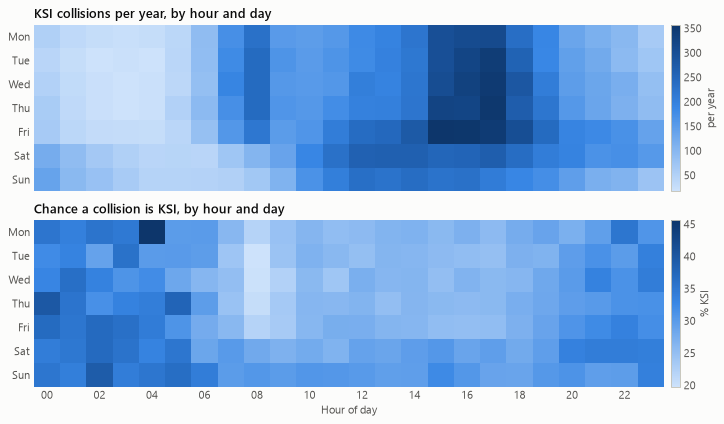

{'peak_count_day': 'Fri', 'peak_count_hour': 15, 'peak_count_value': 357, 'peak_rate_day': 'Mon', 'peak_rate_hour': 4, 'peak_rate_value': 45.6, 'rate_min': 19.8}


In [6]:
order = [2, 3, 4, 5, 6, 7, 1]
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
counts = col.pivot_table(index="weekday", columns="hour", values="ksi_adj", aggfunc="sum").loc[order] / len(M["data"]["years"])
rates = sev.pivot_table(index="weekday", columns="hour", values="ksi", aggfunc="mean").loc[order] * 100

fig, axes = plt.subplots(2, 1, figsize=(10, 5.4), sharex=True)
for ax, data, title, unit in [(axes[0], counts, "KSI collisions per year, by hour and day", "per year"),
                              (axes[1], rates, "Chance a collision is KSI, by hour and day", "% KSI")]:
    im = ax.imshow(data.values, cmap=BLUES, aspect="auto")
    ax.set_yticks(range(7), names)
    ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
    ax.set_title(title)
    ax.spines[["left", "bottom"]].set_visible(False)
    fig.colorbar(im, ax=ax, label=unit, pad=.01)
axes[1].set_xlabel("Hour of day")
fig.tight_layout()
save(fig, "fig03_hour_day_heatmap")

peak = counts.stack().idxmax()
night = rates.stack().idxmax()
M["eda"] = {
    "peak_count_day": names[order.index(peak[0])], "peak_count_hour": int(peak[1]), "peak_count_value": round(float(counts.loc[peak])),
    "peak_rate_day": names[order.index(night[0])], "peak_rate_hour": int(night[1]), "peak_rate_value": round(float(rates.loc[night]), 1),
    "rate_min": round(float(rates.min().min()), 1),
}
print(M["eda"])

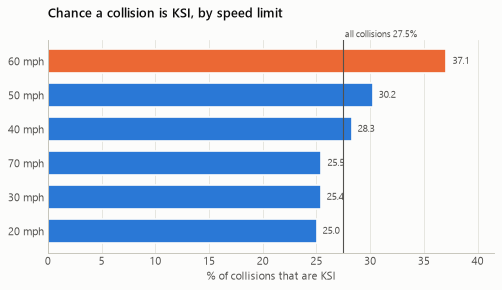

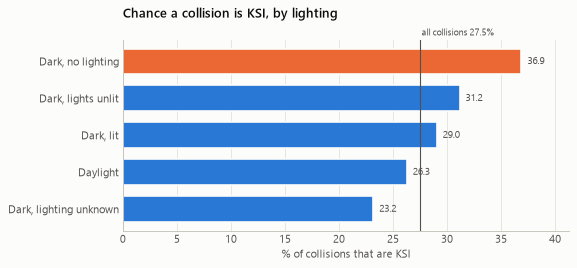

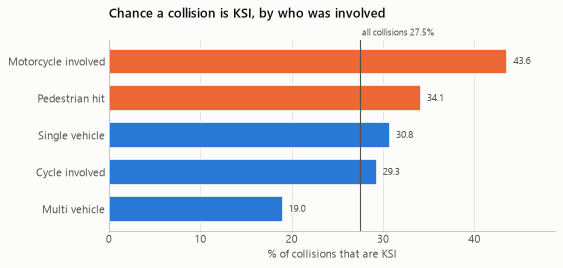

{'20 mph': 25.0, '30 mph': 25.4, '40 mph': 28.3, '50 mph': 30.2, '60 mph': 37.1, '70 mph': 25.5} {'Cycle involved': 29.3, 'Motorcycle involved': 43.6, 'Multi vehicle': 19.0, 'Pedestrian hit': 34.1, 'Single vehicle': 30.8}


In [7]:
base = float(sev["ksi"].mean() * 100)


def rate(by, min_n=300):
    g = sev.groupby(by)["ksi"].agg(["size", "mean"])
    g = g[(g["size"] >= min_n) & (g.index != "Unknown")]
    return (g["mean"] * 100)


speed_rate = rate("speed_band")
light_rate = rate("light")
user_rate = rate("road_user")
road_rate = rate("road_form")

fig = hbar(speed_rate.reindex(["70 mph", "60 mph", "50 mph", "40 mph", "30 mph", "20 mph"])[::-1], "Chance a collision is KSI, by speed limit", "% of collisions that are KSI", base, f"all collisions {base:.1f}%", highlight=["60 mph"])
save(fig, "fig04_speed_limit")
fig = hbar(light_rate, "Chance a collision is KSI, by lighting", "% of collisions that are KSI", base, f"all collisions {base:.1f}%", highlight=["Dark, no lighting"])
save(fig, "fig05_lighting")
fig = hbar(user_rate, "Chance a collision is KSI, by who was involved", "% of collisions that are KSI", base, f"all collisions {base:.1f}%", highlight=["Motorcycle involved", "Pedestrian hit"])
save(fig, "fig06_road_user")

M["eda"].update({
    "base_rate": round(base, 2),
    "speed_rate": {k: round(float(v), 1) for k, v in speed_rate.items()},
    "light_rate": {k: round(float(v), 1) for k, v in light_rate.items()},
    "user_rate": {k: round(float(v), 1) for k, v in user_rate.items()},
    "road_rate": {k: round(float(v), 1) for k, v in road_rate.items()},
    "user_share": {k: round(float(v) * 100, 1) for k, v in sev["road_user"].value_counts(normalize=True).items()},
})
print(M["eda"]["speed_rate"], M["eda"]["user_rate"])

## 4. Hotspot discovery with DBSCAN (Module IV)

**Why DBSCAN.** K-Means forces every collision into a cluster and assumes round clusters of similar size. Most severe collisions are isolated, and a real black spot is a small dense patch. DBSCAN finds dense regions of any shape and leaves everything else as noise, without asking for the number of clusters.

Eastings and northings are metres on the British National Grid, so plain Euclidean distance is real distance on the ground.

In [8]:
pts = col[col["ksi_adj"] >= .5].copy()
xy = pts[["e", "n"]].to_numpy()

def named_road(values):
    named = values[values != "Local road"]
    return (named if len(named) else values).mode().iat[0]


def span(frame):
    return np.hypot(frame["e"].max() - frame["e"].min(), frame["n"].max() - frame["n"].min())


grid_rows = []
for eps in (100, 150, 200, 250):
    for ms in (6, 8, 10, 12):
        lab = DBSCAN(eps=eps, min_samples=ms, algorithm="kd_tree", n_jobs=-1).fit_predict(xy)
        clustered = pd.DataFrame({"e": xy[lab >= 0, 0], "n": xy[lab >= 0, 1], "c": lab[lab >= 0]})
        spans = clustered.groupby("c").apply(span, include_groups=False)
        grid_rows.append({"eps": eps, "min_samples": ms, "clusters": len(spans), "clustered_pct": round((lab >= 0).mean() * 100, 2),
                          "largest": int(clustered["c"].value_counts().max()), "max_span_m": round(float(spans.max())), "p95_span_m": round(float(spans.quantile(.95)))})
dbgrid = pd.DataFrame(grid_rows)
dbgrid.to_csv(RES / "dbscan_grid.csv", index=False)
dbgrid

,eps,min_samples,clusters,clustered_pct,largest,max_span_m,p95_span_m
0,100,6,804,6.11,68,982,418
1,100,8,320,3.13,54,853,424
2,100,10,143,1.68,53,678,408
3,100,12,61,0.86,48,589,407
4,150,6,1320,12.02,345,3167,775
5,150,8,584,7.07,216,2600,840
6,150,10,304,4.51,132,1433,905
7,150,12,189,3.12,130,1426,834
8,200,6,1728,18.72,1807,13038,1107
9,200,8,852,12.15,790,5909,1291


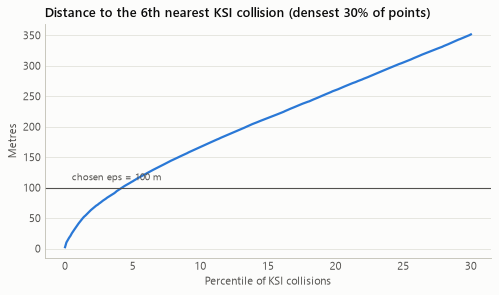

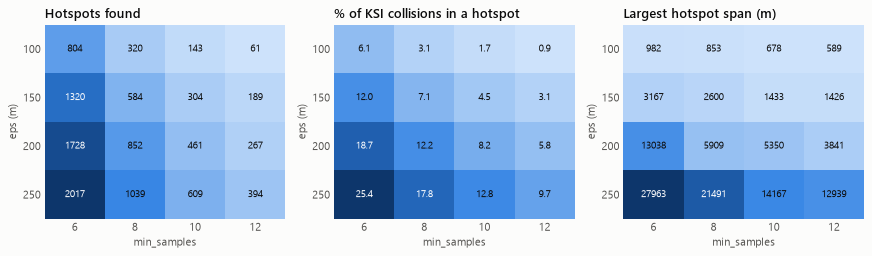

{'ksi_points': 124459, 'eps': 100, 'min_samples': 6, 'count': 804, 'clustered_pct': 6.11, 'noise_pct': 93.89, 'median_span_m': 173, 'max_span_m': 982, 'median_size': 7, 'largest_size': 68, 'pattern_counts': {'Cycle': 295, 'Pedestrian': 216, 'Junction': 104, 'Motorcycle': 98, 'Darkness': 56, 'High speed': 35}, 'top5': [{'rank': 1, 'authority': 'Lambeth', 'road': 'A23', 'ksi': 68, 'fatal': 5, 'span': 885, 'pattern': 'Cycle'}, {'rank': 2, 'authority': 'Westminster', 'road': 'A40', 'ksi': 63, 'fatal': 1, 'span': 909, 'pattern': 'Cycle'}, {'rank': 3, 'authority': 'Lambeth', 'road': 'A3', 'ksi': 57, 'fatal': 2, 'span': 831, 'pattern': 'Cycle'}, {'rank': 4, 'authority': 'Hackney', 'road': 'A1202', 'ksi': 57, 'fatal': 1, 'span': 982, 'pattern': 'Cycle'}, {'rank': 5, 'authority': 'Westminster', 'road': 'A4', 'ksi': 54, 'fatal': 1, 'span': 832, 'pattern': 'Cycle'}], 'top_authorities': {'Westminster': 40, 'Lambeth': 35, 'Southwark': 35, 'Tower Hamlets': 28, 'Wandsworth': 28, 'Kensington and Chels

,authority,road,ksi_collisions,fatal,span_m,pattern
hotspot,,,,,,
50,Lambeth,A23,68,5,885.0,Cycle
55,Westminster,A40,63,1,909.0,Cycle
141,Lambeth,A3,57,2,831.0,Cycle
137,Hackney,A1202,57,1,982.0,Cycle
188,Westminster,A4,54,1,832.0,Cycle
44,Kensington and Chelsea,A402,47,0,931.0,Motorcycle
9,Westminster,A401,36,1,486.0,Pedestrian
27,Lambeth,A202,35,0,458.0,Cycle
199,City of London,A3,35,0,498.0,Cycle


In [9]:
# a usable site is street-scale: keep settings whose largest cluster stays under 1 km, then take the most sites
usable = dbgrid[dbgrid["max_span_m"] <= 1000]
pick = (usable if len(usable) else dbgrid).sort_values(["clusters", "clustered_pct"], ascending=False).iloc[0]
EPS, MS = int(pick["eps"]), int(pick["min_samples"])

kd = NearestNeighbors(n_neighbors=MS, n_jobs=-1).fit(xy).kneighbors(xy)[0][:, -1]
fig, ax = plt.subplots(figsize=(7.2, 3.8))
quantiles = np.linspace(0, 30, 300)
ax.plot(quantiles, np.percentile(kd, quantiles), color=BLUE)
ax.axhline(EPS, color=INK2, linewidth=1)
ax.text(.5, EPS + 12, f"chosen eps = {EPS} m", color=INK2, fontsize=9)
ax.set(title=f"Distance to the {MS}th nearest KSI collision (densest 30% of points)", xlabel="Percentile of KSI collisions", ylabel="Metres")
ax.grid(axis="y")
save(fig, "fig07_k_distance")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, metric, title in zip(axes, ["clusters", "clustered_pct", "max_span_m"], ["Hotspots found", "% of KSI collisions in a hotspot", "Largest hotspot span (m)"]):
    table = dbgrid.pivot(index="eps", columns="min_samples", values=metric)
    ax.imshow(table.values, cmap=BLUES, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    limit = table.values.min() + .6 * (table.values.max() - table.values.min())
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            ax.text(j, i, f"{v:.1f}" if metric == "clustered_pct" else f"{int(v)}", ha="center", va="center", fontsize=9, color="white" if v > limit else INK)
    ax.set(title=title, xlabel="min_samples", ylabel="eps (m)")
    ax.spines[["left", "bottom"]].set_visible(False)
fig.tight_layout()
save(fig, "fig08_dbscan_sensitivity")

pts["hotspot"] = DBSCAN(eps=EPS, min_samples=MS, algorithm="kd_tree", n_jobs=-1).fit_predict(xy)
inside = pts[pts["hotspot"] >= 0].copy()
inside["high_speed"] = (inside["speed_limit"] >= 50).astype(int)
inside["dark"] = (inside["light_conditions"] >= 4).astype(int)
inside["at_junction"] = inside["junction_detail"].isin([13, 16, 17, 18, 19]).astype(int)

hs = inside.groupby("hotspot").agg(
    ksi_collisions=("ksi_adj", "size"), fatal=("fatal", "sum"), lat=("latitude", "mean"), lon=("longitude", "mean"),
    e=("e", "mean"), n=("n", "mean"), authority=("authority", lambda s: s.mode().iat[0]), road=("road_name", named_road),
    pedestrian=("pedestrian", "mean"), motorcycle=("motorcycle", "mean"), pedal_cycle=("pedal_cycle", "mean"),
    dark=("dark", "mean"), at_junction=("at_junction", "mean"), high_speed=("high_speed", "mean"))
hs["span_m"] = inside.groupby("hotspot").apply(span, include_groups=False).round()
all_dark = float((col.loc[col["ksi_adj"] >= .5, "light_conditions"] >= 4).mean())
all_junction = float(col.loc[col["ksi_adj"] >= .5, "junction_detail"].isin([13, 16, 17, 18, 19]).mean())
national = {"pedestrian": float(pts["pedestrian"].mean()), "motorcycle": float(pts["motorcycle"].mean()), "pedal_cycle": float(pts["pedal_cycle"].mean()),
            "dark": all_dark, "at_junction": all_junction, "high_speed": float((pts["speed_limit"] >= 50).mean())}
REVIEW = {"pedestrian": "Pedestrian crossing and speed review", "motorcycle": "Motorcycle route and junction visibility review",
          "pedal_cycle": "Cycle separation and junction protection review", "dark": "Lighting and conspicuity audit",
          "at_junction": "Junction layout and signal review", "high_speed": "Speed limit and enforcement review"}
PATTERN = {"pedestrian": "Pedestrian", "motorcycle": "Motorcycle", "pedal_cycle": "Cycle", "dark": "Darkness", "at_junction": "Junction", "high_speed": "High speed"}


def dominant(row):
    ratios = {k: row[k] / national[k] for k in national if row[k] >= .3}
    return max(ratios, key=ratios.get) if ratios else "at_junction"


hs["pattern"] = hs.apply(dominant, axis=1)
hs["review"] = hs["pattern"].map(REVIEW)
hs["pattern"] = hs["pattern"].map(PATTERN)
hs = hs.sort_values(["ksi_collisions", "fatal"], ascending=False)
hs["rank"] = range(1, len(hs) + 1)
hs.to_csv(RES / "hotspots.csv")

M["hotspots"] = {
    "ksi_points": len(pts), "eps": EPS, "min_samples": MS, "count": len(hs), "clustered_pct": round(float((pts["hotspot"] >= 0).mean()) * 100, 2),
    "noise_pct": round(float((pts["hotspot"] < 0).mean()) * 100, 2), "median_span_m": round(float(hs["span_m"].median())), "max_span_m": round(float(hs["span_m"].max())),
    "median_size": int(hs["ksi_collisions"].median()), "largest_size": int(hs["ksi_collisions"].max()),
    "pattern_counts": {k: int(v) for k, v in hs["pattern"].value_counts().items()},
    "top5": [{"rank": int(r["rank"]), "authority": r["authority"], "road": r["road"], "ksi": int(r["ksi_collisions"]), "fatal": int(r["fatal"]), "span": int(r["span_m"]), "pattern": r["pattern"]} for _, r in hs.head(5).iterrows()],
    "top_authorities": {k: int(v) for k, v in hs["authority"].value_counts().head(8).items()},
    "grid": dbgrid.to_dict("records"),
}
print({k: v for k, v in M["hotspots"].items() if k not in ("grid",)})
hs[["authority", "road", "ksi_collisions", "fatal", "span_m", "pattern"]].head(10)

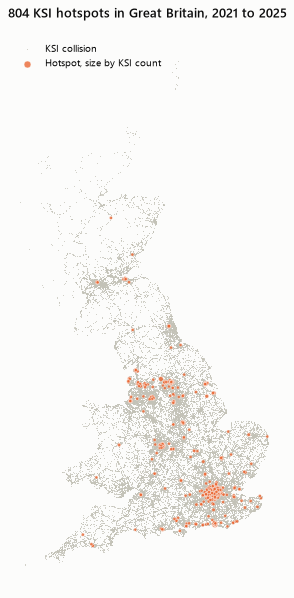

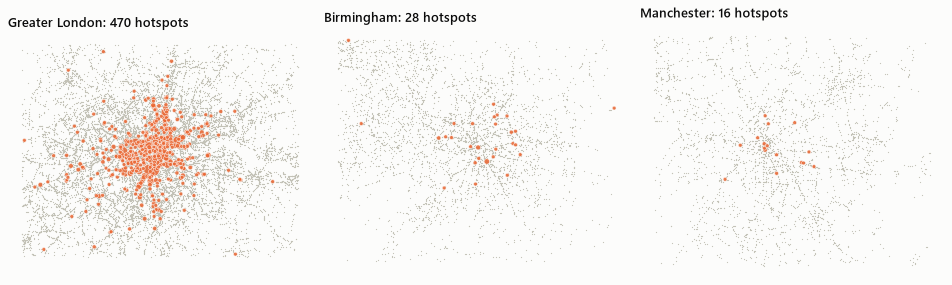

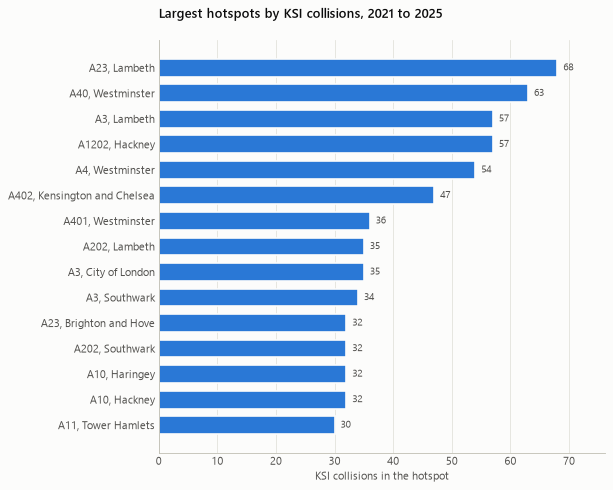

In [10]:
sample = pts.sample(min(len(pts), 60000), random_state=SEED)
fig, ax = plt.subplots(figsize=(6.4, 9))
ax.scatter(sample["e"], sample["n"], s=.5, color=AXIS, linewidths=0, rasterized=True, label="KSI collision")
ax.scatter(hs["e"], hs["n"], s=np.clip(hs["ksi_collisions"], 8, 90), color=ORANGE, alpha=.8, linewidths=.4, edgecolor=SURFACE, label="Hotspot, size by KSI count")
ax.set_aspect("equal")
ax.set_title(f"{len(hs)} KSI hotspots in Great Britain, 2021 to 2025")
ax.axis("off")
ax.legend(loc="upper left", markerscale=1, fontsize=9)
save(fig, "fig09_gb_hotspots")

CITIES = {"Greater London": (500000, 565000, 155000, 205000), "Birmingham": (390000, 425000, 272000, 300000), "Manchester": (372000, 402000, 385000, 410000)}
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (city, (x0, x1, y0, y1)) in zip(axes, CITIES.items()):
    p = pts[pts["e"].between(x0, x1) & pts["n"].between(y0, y1)]
    h = hs[hs["e"].between(x0, x1) & hs["n"].between(y0, y1)]
    ax.scatter(p["e"], p["n"], s=1.2, color=AXIS, linewidths=0, rasterized=True)
    ax.scatter(h["e"], h["n"], s=np.clip(h["ksi_collisions"] * 1.5, 12, 160), color=ORANGE, alpha=.85, linewidths=.5, edgecolor=SURFACE)
    ax.set_aspect("equal")
    ax.set_title(f"{city}: {len(h)} hotspots")
    ax.axis("off")
fig.tight_layout()
save(fig, "fig10_city_hotspots")

top15 = hs.head(15).copy()
top15["name"] = top15["road"] + ", " + top15["authority"]
fig = hbar(top15.set_index("name")["ksi_collisions"].groupby(level=0).max(), "Largest hotspots by KSI collisions, 2021 to 2025", "KSI collisions in the hotspot", fmt="{:.0f}")
save(fig, "fig11_top_hotspots")

### 4.1 Do hotspots persist?

A hotspot is only useful if it predicts where severe crashes happen next. Hotspots are rediscovered on 2021 to 2024 only, then tested on 2025. The comparison is the same number of KSI locations drawn at random from the past. Hotspot points sit on top of each other, so they cover far less ground than the same number of scattered points. The test therefore reports both the share of 2025 KSI collisions reached and that share per square kilometre treated.

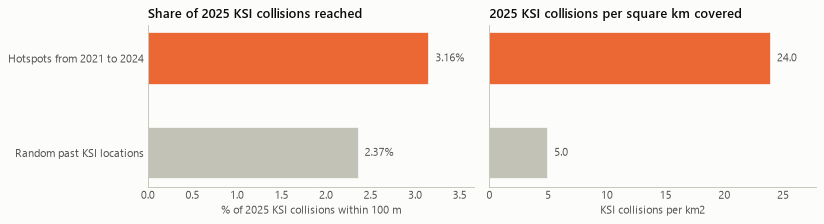

{'past_hotspots': 476, 'member_points': 4155, 'future_ksi': 26645, 'hot_cover_pct': 3.16, 'random_cover_pct': 2.37, 'random_sd': 0.064, 'cover_ratio': 1.34, 'hot_area_km2': 35.1, 'random_area_km2': 126.0, 'hot_density': np.float64(23.97), 'random_density': 5.0, 'density_ratio': np.float64(4.79)}


In [11]:
past, future = pts[pts["collision_year"] <= 2024], pts[pts["collision_year"] == 2025]
past_xy, fut_xy = past[["e", "n"]].to_numpy(), future[["e", "n"]].to_numpy()
past_lab = DBSCAN(eps=EPS, min_samples=MS, algorithm="kd_tree", n_jobs=-1).fit_predict(past_xy)
members = past_xy[past_lab >= 0]


def covered(sites):
    near = NearestNeighbors(radius=EPS, n_jobs=-1).fit(sites).radius_neighbors(fut_xy, return_distance=False)
    return np.mean([len(x) > 0 for x in near]) * 100


def footprint_km2(sites, cell=25):
    """Area of the union of EPS-radius discs, measured on a fine grid."""
    r = int(np.ceil(EPS / cell))
    dx, dy = np.meshgrid(np.arange(-r, r + 1), np.arange(-r, r + 1))
    keep = (dx ** 2 + dy ** 2) * cell ** 2 <= EPS ** 2
    ox, oy = dx[keep], dy[keep]
    occupied = set()
    for x, y in (sites // cell).astype(np.int64):
        occupied.update(zip((x + ox).tolist(), (y + oy).tolist()))
    return len(occupied) * (cell / 1000) ** 2


hot_cover, hot_area = covered(members), footprint_km2(members)
others = past_xy[past_lab < 0]
draws = [others[rng.choice(len(others), len(members), replace=False)] for _ in range(20)]
random_cover = [covered(d) for d in draws]
random_area = float(np.mean([footprint_km2(d) for d in draws[:5]]))
hot_density = hot_cover / 100 * len(future) / hot_area
random_density = float(np.mean(random_cover)) / 100 * len(future) / random_area

fig, axes = plt.subplots(1, 2, figsize=(10.4, 2.9))
labels_bar = ["Random past KSI locations", "Hotspots from 2021 to 2024"]
for ax, values, title, xlabel, fmt in [(axes[0], [float(np.mean(random_cover)), float(hot_cover)], "Share of 2025 KSI collisions reached", f"% of 2025 KSI collisions within {EPS} m", "{:.2f}%"),
                                       (axes[1], [random_density, hot_density], "2025 KSI collisions per square km covered", "KSI collisions per km2", "{:.1f}")]:
    ax.barh(labels_bar, values, color=[AXIS, ORANGE], height=.56, edgecolor=SURFACE, linewidth=1.5)
    for y, v in enumerate(values):
        ax.text(v, y, "  " + fmt.format(v), va="center", color=INK2)
    ax.set(title=title, xlabel=xlabel)
    ax.margins(x=.16)
axes[1].set_yticklabels([])
fig.tight_layout()
save(fig, "fig12_hotspot_persistence")

M["persistence"] = {
    "past_hotspots": int(past_lab.max() + 1), "member_points": len(members), "future_ksi": len(future),
    "hot_cover_pct": round(float(hot_cover), 2), "random_cover_pct": round(float(np.mean(random_cover)), 2), "random_sd": round(float(np.std(random_cover)), 3),
    "cover_ratio": round(float(hot_cover / np.mean(random_cover)), 2), "hot_area_km2": round(hot_area, 1), "random_area_km2": round(random_area, 1),
    "hot_density": round(hot_density, 2), "random_density": round(random_density, 2), "density_ratio": round(hot_density / random_density, 2),
}
print(M["persistence"])

## 5. Association rules with Apriori (Module V)

**Question.** Which combinations of conditions make a collision more likely to be KSI?

Only injury-based records are used. Rules are mined on 2021 to 2024 and checked on 2025, because a rule that holds only in the data that produced it is not knowledge. Support, confidence and lift follow the reference paper. A rule's lift is how many times more likely KSI is under the antecedent than overall.

In [12]:
ITEM_COLS = {"speed_band": "Speed", "road_class": "Road", "road_form": "Layout", "junction": "Junction", "crossing": "Crossing",
             "light": "Light", "weather": "Weather", "surface": "Surface", "area": "Area", "hour_band": "Time", "day_type": "Day"}
FLAG_ITEMS = {"pedestrian": "Pedestrian hit", "motorcycle": "Motorcycle involved", "pedal_cycle": "Cycle involved", "hgv": "HGV involved",
              "bus": "Bus involved", "young_driver": "Driver under 25", "older_driver": "Driver 70 or over", "single_vehicle": "Single vehicle",
              "left_road": "Left the road", "overturned": "Overturned", "hit_tree_or_pole": "Hit tree or pole"}


def to_items(frame):
    out = {}
    for c, tag in ITEM_COLS.items():
        for value in sorted(set(frame[c].unique()) - {"Unknown", "Other"}):
            out[f"{tag}: {value}"] = (frame[c] == value).to_numpy()
    for c, tag in FLAG_ITEMS.items():
        out[tag] = (frame[c] == 1).to_numpy()
    out["KSI"] = (frame["ksi"] == 1).to_numpy()
    return pd.DataFrame(out)


sev_train, sev_test = sev[sev["collision_year"] <= 2024], sev[sev["collision_year"] == 2025]
items_train, items_test = to_items(sev_train), to_items(sev_test)
for missing_item in set(items_train.columns) - set(items_test.columns):
    items_test[missing_item] = False


def mine(items, min_support, max_len):
    start = time.time()
    freq = apriori(items, min_support=min_support, use_colnames=True, max_len=max_len, low_memory=True)
    rules = association_rules(freq, num_itemsets=len(items), metric="lift", min_threshold=1.0)
    rules = rules[rules["consequents"] == frozenset({"KSI"})].copy()
    return freq, rules, time.time() - start


def prune(rules):
    """Drop a rule when a shorter rule inside it already reaches the same confidence."""
    rules = rules.sort_values("confidence", ascending=False)
    kept = []
    by_len = rules.assign(size=rules["antecedents"].map(len)).sort_values(["size", "confidence"], ascending=[True, False])
    for _, r in by_len.iterrows():
        if not any(k["antecedents"] < r["antecedents"] and k["confidence"] >= r["confidence"] - .03 for k in kept):
            kept.append(r)
    return pd.DataFrame(kept)


freq, rules_all, mine_seconds = mine(items_train, .01, 4)
strong = rules_all[(rules_all["lift"] >= 1.3) & (rules_all["confidence"] >= .35)]
rules = prune(strong).reset_index(drop=True)


def check(antecedent, items):
    mask = items[list(antecedent)].all(axis=1)
    n = int(mask.sum())
    return n, float(items.loc[mask, "KSI"].mean()) if n else np.nan


base_tr, base_te = float(items_train["KSI"].mean()), float(items_test["KSI"].mean())
held = [check(a, items_test) for a in rules["antecedents"]]
rules["test_n"] = [h[0] for h in held]
rules["test_confidence"] = [h[1] for h in held]
rules["test_lift"] = rules["test_confidence"] / base_te


def p_value(a):
    mask = items_train[list(a)].all(axis=1)
    table = pd.crosstab(mask, items_train["KSI"])
    return chi2_contingency(table)[1]


rules["p_value"] = [p_value(a) for a in rules["antecedents"]]
rules["rule"] = rules["antecedents"].map(lambda a: " + ".join(sorted(a)))
rules = rules.sort_values("lift", ascending=False).reset_index(drop=True)
out_cols = ["rule", "support", "confidence", "lift", "test_n", "test_confidence", "test_lift", "p_value"]
rules[out_cols].to_csv(RES / "association_rules.csv", index=False)

stable = rules[(rules["test_lift"] >= 1.2) & (rules["test_n"] >= 100)]
THEMES = {"Motorcycle": "Motorcycle involved", "Pedestrian": "Pedestrian hit", "Cycle": "Cycle involved", "Overturned": "Overturned", "Fixed object": "Hit tree or pole",
          "Left the road": "Left the road", "No street lighting": "Light: Dark, no lighting", "Rural, 60 mph": "Speed: 60 mph", "Older driver": "Driver 70 or over", "HGV": "HGV involved"}
theme_rows = []
for theme, item in THEMES.items():
    pool = rules[rules["antecedents"].map(lambda a: item in a) & (rules["test_n"] >= 100)]
    if theme != "Motorcycle":
        pool = pool[pool["antecedents"].map(lambda a: "Motorcycle involved" not in a)]
    if len(pool):
        theme_rows.append(pool.sort_values("lift", ascending=False).iloc[0].to_dict() | {"theme": theme})
themed = pd.DataFrame(theme_rows).sort_values("lift", ascending=False).drop_duplicates("rule").reset_index(drop=True)
M["rules"] = {
    "transactions": len(items_train), "items": items_train.shape[1], "frequent_itemsets": len(freq), "ksi_rules_raw": len(rules_all),
    "strong": len(strong), "kept": len(rules), "stable": len(stable), "stable_pct": round(len(stable) / len(rules) * 100, 1),
    "seconds": round(mine_seconds, 1), "base_train": round(base_tr * 100, 2), "base_test": round(base_te * 100, 2),
    "lift_corr": round(float(rules[["lift", "test_lift"]].corr().iloc[0, 1]), 3), "median_lift_shrink_pct": round(float(((rules["lift"] - rules["test_lift"]) / rules["lift"]).median()) * 100, 1),
    "bonferroni_pass": int((rules["p_value"] < .001 / max(len(rules_all), 1)).sum()),
    "top": [{"rule": r["rule"], "support": round(float(r["support"]) * 100, 2), "confidence": round(float(r["confidence"]) * 100, 1), "lift": round(float(r["lift"]), 2),
             "test_confidence": round(float(r["test_confidence"]) * 100, 1), "test_lift": round(float(r["test_lift"]), 2)} for _, r in rules.head(12).iterrows()],
    "themes": [{"theme": r["theme"], "rule": r["rule"], "support": round(float(r["support"]) * 100, 2), "confidence": round(float(r["confidence"]) * 100, 1), "lift": round(float(r["lift"]), 2),
                "test_confidence": round(float(r["test_confidence"]) * 100, 1), "test_lift": round(float(r["test_lift"]), 2), "test_n": int(r["test_n"])} for _, r in themed.iterrows()],
}
print({k: v for k, v in M["rules"].items() if k != "top"})
rules[out_cols].head(12).round(3)

{'transactions': 221193, 'items': 63, 'frequent_itemsets': 20684, 'ksi_rules_raw': 1657, 'strong': 579, 'kept': 109, 'stable': 107, 'stable_pct': 98.2, 'seconds': 19.9, 'base_train': 27.64, 'base_test': 27.0, 'lift_corr': 0.946, 'median_lift_shrink_pct': 0.9, 'bonferroni_pass': 109, 'themes': [{'theme': 'Motorcycle', 'rule': 'Left the road + Motorcycle involved', 'support': 1.35, 'confidence': 66.7, 'lift': 2.41, 'test_confidence': 59.1, 'test_lift': 2.19, 'test_n': 2032}, {'theme': 'Rural, 60 mph', 'rule': 'Left the road + Speed: 60 mph + Surface: Dry', 'support': 1.68, 'confidence': 46.0, 'lift': 1.66, 'test_confidence': 44.2, 'test_lift': 1.64, 'test_n': 2710}, {'theme': 'Overturned', 'rule': 'Left the road + Overturned + Surface: Dry', 'support': 1.11, 'confidence': 44.2, 'lift': 1.6, 'test_confidence': 40.8, 'test_lift': 1.51, 'test_n': 2002}, {'theme': 'Pedestrian', 'rule': 'Light: Dark, lit + Pedestrian hit', 'support': 1.72, 'confidence': 42.7, 'lift': 1.55, 'test_confidence': 

,rule,support,confidence,lift,test_n,test_confidence,test_lift,p_value
0,Left the road + Motorcycle involved,0.013,0.667,2.412,2032,0.591,2.189,0.0
1,Motorcycle involved + Speed: 60 mph,0.015,0.637,2.306,1810,0.590,2.183,0.0
2,Area: Rural + Day: Weekend + Motorcycle involved,0.010,0.602,2.180,1404,0.586,2.171,0.0
3,Motorcycle involved + Single vehicle + Surface...,0.011,0.601,2.175,1919,0.526,1.947,0.0
4,Area: Rural + Layout: Single carriageway + Mot...,0.024,0.585,2.116,3399,0.560,2.074,0.0
5,Motorcycle involved + Single vehicle,0.014,0.568,2.055,2608,0.503,1.862,0.0
6,Area: Rural + Motorcycle involved,0.029,0.553,2.002,4482,0.536,1.986,0.0
7,Day: Weekend + Junction: Not at junction + Mot...,0.010,0.541,1.956,1569,0.516,1.910,0.0
8,Motorcycle involved + Overturned,0.011,0.522,1.889,1806,0.493,1.825,0.0
9,Day: Weekend + Motorcycle involved,0.018,0.509,1.840,3754,0.423,1.566,0.0


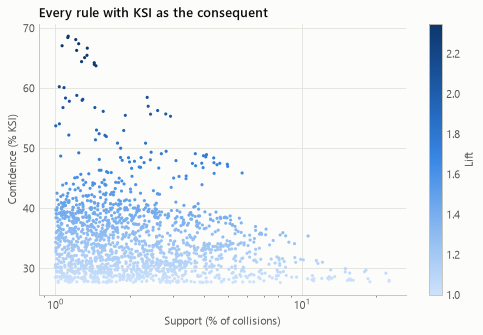

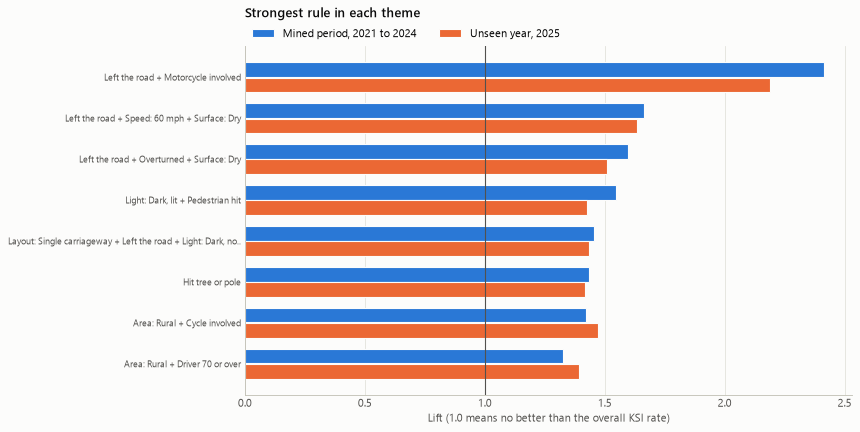

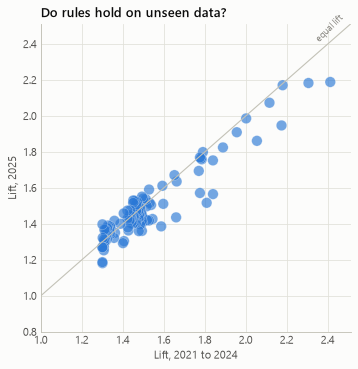

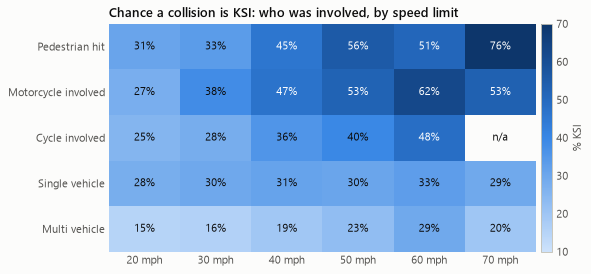

In [13]:
fig, ax = plt.subplots(figsize=(7.4, 4.4))
points = ax.scatter(rules_all["support"] * 100, rules_all["confidence"] * 100, c=rules_all["lift"], cmap=BLUES, s=8, linewidths=0, vmin=1, vmax=max(2.2, rules_all["lift"].quantile(.995)))
ax.set(title="Every rule with KSI as the consequent", xlabel="Support (% of collisions)", ylabel="Confidence (% KSI)", xscale="log")
ax.grid(True)
ax.set_axisbelow(True)
fig.colorbar(points, ax=ax, label="Lift")
save(fig, "fig13_rule_landscape")

top = themed.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.8, .52 * len(top) + 1.5))
y = np.arange(len(top))
ax.barh(y + .19, top["lift"], height=.36, color=BLUE, edgecolor=SURFACE, label="Mined period, 2021 to 2024")
ax.barh(y - .19, top["test_lift"], height=.36, color=ORANGE, edgecolor=SURFACE, label="Unseen year, 2025")
ax.set_yticks(y, [r if len(r) < 62 else r[:60] + ".." for r in top["rule"]], fontsize=8.5)
ax.axvline(1, color=INK2, linewidth=1)
ax.set_title("Strongest rule in each theme", pad=26)
ax.set(xlabel="Lift (1.0 means no better than the overall KSI rate)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncols=2, borderaxespad=.2)
ax.grid(axis="x")
ax.set_axisbelow(True)
save(fig, "fig14_top_rules")

fig, ax = plt.subplots(figsize=(5, 5))
limit = float(np.nanmax([rules["lift"].max(), rules["test_lift"].max()])) + .1
ax.plot([1, limit], [1, limit], color=AXIS, linewidth=1)
ax.scatter(rules["lift"], rules["test_lift"], s=np.clip(rules["test_n"] / 15, 8, 90), color=BLUE, alpha=.65, linewidths=.3, edgecolor=SURFACE)
ax.set(title="Do rules hold on unseen data?", xlabel="Lift, 2021 to 2024", ylabel="Lift, 2025", xlim=(1, limit), ylim=(.8, limit))
ax.text(limit - .03, limit - .1, "equal lift", color=MUTED, fontsize=8.5, ha="right", rotation=45)
ax.grid(True)
ax.set_axisbelow(True)
save(fig, "fig15_rule_stability")

inter = sev.pivot_table(index="road_user", columns="speed_band", values="ksi", aggfunc="mean") * 100
sizes = sev.pivot_table(index="road_user", columns="speed_band", values="ksi", aggfunc="size")
inter = inter.where(sizes >= 200).loc[lambda d: d.mean(axis=1).sort_values(ascending=False).index, ["20 mph", "30 mph", "40 mph", "50 mph", "60 mph", "70 mph"]]
fig, ax = plt.subplots(figsize=(8.2, 3.7))
im = ax.imshow(inter.values, cmap=BLUES, aspect="auto", vmin=10, vmax=70)
ax.set_xticks(range(inter.shape[1]), inter.columns)
ax.set_yticks(range(inter.shape[0]), inter.index)
for i in range(inter.shape[0]):
    for j in range(inter.shape[1]):
        v = inter.iloc[i, j]
        ax.text(j, i, "n/a" if pd.isna(v) else f"{v:.0f}%", ha="center", va="center", fontsize=10, color="white" if (not pd.isna(v) and v > 42) else INK)
ax.set_title("Chance a collision is KSI: who was involved, by speed limit")
ax.spines[["left", "bottom"]].set_visible(False)
fig.colorbar(im, ax=ax, label="% KSI", pad=.01)
save(fig, "fig16_interaction_heatmap")
M["rules"]["interaction"] = {i: {c: (None if pd.isna(v) else round(float(v), 1)) for c, v in row.items()} for i, row in inter.iterrows()}

### 5.1 Testing the reference paper's claim

Kumar and Toshniwal (2015) segment accidents with K-Modes first, then mine rules inside each segment, and report that segmentation reveals rules the entire data set hides. They worked on 11,574 accidents from Dehradun and used six clusters. This section repeats the idea at a larger scale with the same k, and adds a test the paper does not run: do those hidden rules survive on a year the mining never saw? K-Modes suits this step because the attributes are categorical, and the mean used by K-Means has no meaning for them.

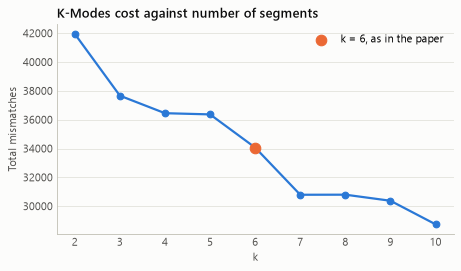

C:\Users\ANEXUS\Desktop\DMBI-CAs-D15A-Gr09\.venv\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


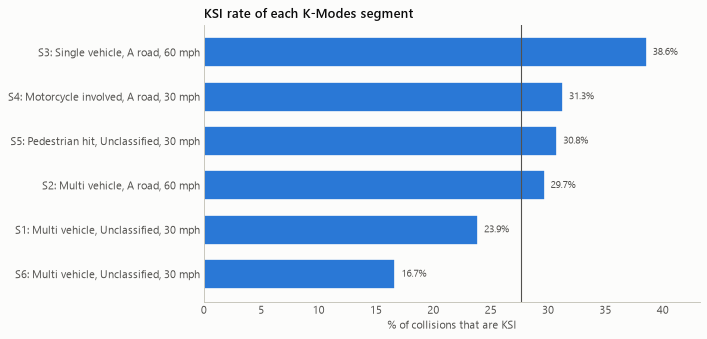

{2: 41951.0, 3: 37664.0, 4: 36449.0, 5: 36366.0, 6: 34064.0, 7: 30791.0, 8: 30796.0, 9: 30375.0, 10: 28742.0} {3: 0.1022, 4: 0.0323, 5: 0.0023, 6: 0.0633, 7: 0.0961, 8: -0.0002, 9: 0.0137, 10: 0.0538}
   segment  collisions  share_pct  ksi_pct            road_user    road_class              light         junction   area speed_band
0        1       69697       31.5     23.9        Multi vehicle  Unclassified           Daylight       T junction  Urban     30 mph
1        2       63039       28.5     29.7        Multi vehicle        A road           Daylight  Not at junction  Rural     60 mph
2        3       10157        4.6     38.6       Single vehicle        A road  Dark, no lighting  Not at junction  Rural     60 mph
3        4       33708       15.2     31.3  Motorcycle involved        A road           Daylight  Not at junction  Urban     30 mph
4        5       27124       12.3     30.8       Pedestrian hit  Unclassified           Daylight  Not at junction  Urban     30 mph
5      

In [14]:
KM_COLS = ["road_user", "road_class", "light", "junction", "area", "speed_band"]
km_sample = sev_train.sample(20000, random_state=SEED)
costs = {}
for k in range(2, 11):
    costs[k] = KModes(n_clusters=k, init="Huang", n_init=2, random_state=SEED).fit(km_sample[KM_COLS].to_numpy()).cost_
cost = pd.Series(costs)
gain = (-cost.diff() / cost.shift()).dropna()
K = 6  # k follows the paper so the comparison is direct

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(cost.index, cost.values, color=BLUE, marker="o", markersize=6)
ax.scatter([K], [cost[K]], color=ORANGE, s=90, zorder=3, label=f"k = {K}, as in the paper")
ax.set(title="K-Modes cost against number of segments", xlabel="k", ylabel="Total mismatches")
ax.grid(axis="y")
ax.legend()
save(fig, "fig17_kmodes_elbow")

km = KModes(n_clusters=K, init="Huang", n_init=3, random_state=SEED).fit(km_sample[KM_COLS].to_numpy())
sev_train, sev_test = sev_train.copy(), sev_test.copy()
sev_train["segment"] = km.predict(sev_train[KM_COLS].to_numpy())
sev_test["segment"] = km.predict(sev_test[KM_COLS].to_numpy())

profile_rows, hidden_rows = [], []
eds_keys = {frozenset(a) for a in rules_all[(rules_all["lift"] >= 1.2)]["antecedents"]}
for seg in range(K):
    part = sev_train[sev_train["segment"] == seg]
    mode = {c: part[c].mode().iat[0] for c in KM_COLS}
    profile_rows.append({"segment": seg + 1, "collisions": len(part), "share_pct": round(len(part) / len(sev_train) * 100, 1), "ksi_pct": round(float(part["ksi"].mean()) * 100, 1), **mode})
    _, seg_rules, _ = mine(to_items(part), .03, 3)
    seg_rules = seg_rules[(seg_rules["lift"] >= 1.2) & (seg_rules["antecedents"].map(len) >= 2)]
    new = seg_rules[~seg_rules["antecedents"].isin(eds_keys)].sort_values("lift", ascending=False)
    part_test = to_items(sev_test[sev_test["segment"] == seg])
    for missing_item in set(items_train.columns) - set(part_test.columns):
        part_test[missing_item] = False
    seg_base = float(part_test["KSI"].mean())
    held_new = [check(a, part_test) for a in new["antecedents"]]
    hold = sum(n >= 50 and c / seg_base >= 1.1 for n, c in held_new)
    hidden_rows.append({"segment": seg + 1, "rules": len(seg_rules), "hidden": len(new), "hidden_holds_2025": hold, "example": " + ".join(sorted(new.iloc[0]["antecedents"])) if len(new) else "",
                        "example_lift": round(float(new.iloc[0]["lift"]), 2) if len(new) else None, "example_conf": round(float(new.iloc[0]["confidence"]) * 100, 1) if len(new) else None})
profile = pd.DataFrame(profile_rows)
hidden = pd.DataFrame(hidden_rows)
profile.to_csv(RES / "kmodes_segments.csv", index=False)
hidden.to_csv(RES / "segment_rules.csv", index=False)

fig, ax = plt.subplots(figsize=(8, .55 * K + 1.2))
seg_labels = [f"S{r.segment}: {r.road_user}, {r.road_class}, {r.speed_band}" for r in profile.itertuples()]
order_seg = np.argsort(profile["ksi_pct"].to_numpy())
ax.barh(np.array(seg_labels)[order_seg], profile["ksi_pct"].to_numpy()[order_seg], color=BLUE, height=.68, edgecolor=SURFACE, linewidth=1.5)
for y, v in enumerate(profile["ksi_pct"].to_numpy()[order_seg]):
    ax.text(v, y, f"  {v:.1f}%", va="center", color=INK2, fontsize=9)
ax.axvline(base_tr * 100, color=INK2, linewidth=1)
ax.set(title="KSI rate of each K-Modes segment", xlabel="% of collisions that are KSI")
ax.margins(x=.12)
save(fig, "fig18_kmodes_segments")

M["kmodes"] = {"k": K, "sample": len(km_sample), "costs": {int(a): int(b) for a, b in cost.items()}, "profile": profile.to_dict("records"), "hidden": hidden.to_dict("records"),
               "hidden_total": int(hidden["hidden"].sum()), "hidden_holds_2025": int(hidden["hidden_holds_2025"].sum()), "segment_rules_total": int(hidden["rules"].sum()), "segment_ksi_min": float(profile["ksi_pct"].min()), "segment_ksi_max": float(profile["ksi_pct"].max())}
print(cost.round().to_dict(), gain.round(4).to_dict())
print(profile.to_string(), hidden.to_string(), sep="\n")

## 6. Severity classification (Module III)

**Question.** Given a collision's context, is it likely to be KSI?

**Split by time, not at random.** Train on 2021 to 2023, tune on 2024, refit on 2021 to 2024, test on 2025. A random split lets a model see the future, and a road authority never gets that.

**Which metric.** KSI is the minority class, so accuracy flatters a model that predicts Slight for everything. PR-AUC and recall carry the decision. ROC-AUC measures ranking.

In [15]:
CONTEXT = ["speed_band", "road_class", "road_form", "junction", "crossing", "light", "weather", "surface", "area", "hour_band", "day_type"]
PEOPLE = ["pedestrian", "motorcycle", "pedal_cycle", "hgv", "bus", "young_driver", "older_driver", "single_vehicle", "number_of_vehicles", "youngest", "oldest"]
MECHANICS = ["left_road", "skidded", "overturned", "hit_fixed_object", "hit_tree_or_pole", "hit_object_in_road"]
ALL_FEATURES = CONTEXT + PEOPLE + MECHANICS


def make_pipe(model, features):
    cats = [c for c in features if c in CONTEXT]
    nums = [c for c in features if c not in CONTEXT]
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats), ("num", "passthrough", nums)])
    return Pipeline([("prep", prep), ("model", model)])


tr = sev[sev["collision_year"] <= 2023]
va = sev[sev["collision_year"] == 2024]
te = sev[sev["collision_year"] == 2025]
fit_all = sev[sev["collision_year"] <= 2024]

CANDIDATES = {
    "Naive Bayes": [BernoulliNB(alpha=a) for a in (.5, 1.0)],
    "Decision Tree": [DecisionTreeClassifier(max_depth=d, min_samples_leaf=100, class_weight="balanced", random_state=SEED) for d in (4, 6, 8, 10, 12)],
    "Random Forest": [RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=25, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED) for d in (10, 14, 18)],
    "AdaBoost": [AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=n, learning_rate=.3, random_state=SEED) for n in (100, 200)],
}
tuning, chosen, thresholds = [], {}, {}
for name, options in CANDIDATES.items():
    best = None
    for model in options:
        pipe = make_pipe(sklearn.base.clone(model), ALL_FEATURES).fit(tr[ALL_FEATURES], tr["ksi"])
        p = pipe.predict_proba(va[ALL_FEATURES])[:, 1]
        pr = average_precision_score(va["ksi"], p)
        tuning.append({"model": name, "params": str({k: v for k, v in model.get_params().items() if k in ("max_depth", "alpha", "n_estimators")}), "val_pr_auc": round(pr, 4), "val_roc_auc": round(roc_auc_score(va["ksi"], p), 4)})
        if best is None or pr > best[0]:
            precision, recall, cuts = precision_recall_curve(va["ksi"], p)
            f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-9)
            best = (pr, model, float(cuts[f1.argmax()]), p)
    chosen[name], thresholds[name] = best[1], best[2]
    if name == "Random Forest":
        val_prob = best[3]
pd.DataFrame(tuning).to_csv(RES / "tuning.csv", index=False)
pd.DataFrame(tuning)

,model,params,val_pr_auc,val_roc_auc
0,Naive Bayes,{'alpha': 0.5},0.3939,0.6417
1,Naive Bayes,{'alpha': 1.0},0.3939,0.6417
2,Decision Tree,{'max_depth': 4},0.4041,0.6396
3,Decision Tree,{'max_depth': 6},0.4290,0.6565
4,Decision Tree,{'max_depth': 8},0.4421,0.6650
5,Decision Tree,{'max_depth': 10},0.4467,0.6677
6,Decision Tree,{'max_depth': 12},0.4453,0.6665
7,Random Forest,"{'max_depth': 10, 'n_estimators': 200}",0.4575,0.6745
8,Random Forest,"{'max_depth': 14, 'n_estimators': 200}",0.4610,0.6784
9,Random Forest,"{'max_depth': 18, 'n_estimators': 200}",0.4615,0.6793


In [16]:
final, probs, rows = {}, {}, []
for name, model in chosen.items():
    pipe = make_pipe(sklearn.base.clone(model), ALL_FEATURES).fit(fit_all[ALL_FEATURES], fit_all["ksi"])
    p = pipe.predict_proba(te[ALL_FEATURES])[:, 1]
    final[name], probs[name] = pipe, p
    yhat = (p >= thresholds[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(te["ksi"], yhat).ravel()
    rows.append({"model": name, "accuracy": accuracy_score(te["ksi"], yhat), "balanced_accuracy": balanced_accuracy_score(te["ksi"], yhat), "precision": precision_score(te["ksi"], yhat),
                 "recall": recall_score(te["ksi"], yhat), "f1": f1_score(te["ksi"], yhat), "roc_auc": roc_auc_score(te["ksi"], p), "pr_auc": average_precision_score(te["ksi"], p),
                 "threshold": thresholds[name], "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)})
scores = pd.DataFrame(rows).sort_values("pr_auc", ascending=False)
scores.to_csv(RES / "severity_scores.csv", index=False)

y_te = te["ksi"].to_numpy()
BEST = scores.iloc[0]["model"]
boot_roc, boot_pr = [], []
for _ in range(200):
    i = rng.integers(0, len(y_te), len(y_te))
    boot_roc.append(roc_auc_score(y_te[i], probs[BEST][i]))
    boot_pr.append(average_precision_score(y_te[i], probs[BEST][i]))

M["severity"] = {
    "train_rows": len(fit_all), "test_rows": len(te), "test_ksi_pct": round(float(y_te.mean()) * 100, 2), "best": BEST,
    "majority_accuracy": round(float(1 - y_te.mean()), 4), "chance_pr_auc": round(float(y_te.mean()), 4),
    "scores": scores.round(4).to_dict("records"), "roc_ci": [round(float(np.percentile(boot_roc, q)), 4) for q in (2.5, 97.5)], "pr_ci": [round(float(np.percentile(boot_pr, q)), 4) for q in (2.5, 97.5)],
    "params": {k: str({a: b for a, b in v.get_params().items() if a in ("max_depth", "alpha", "n_estimators", "min_samples_leaf")}) for k, v in chosen.items()},
}
scores.round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,tn,fp,fn,tp
2,Random Forest,0.5685,0.6236,0.3566,0.7435,0.4820,0.6791,0.4399,0.4561,32303,31825,6083,17637
3,AdaBoost,0.5688,0.6175,0.3540,0.7234,0.4753,0.6696,0.4257,0.3316,32814,31314,6562,17158
1,Decision Tree,0.5473,0.6132,0.3455,0.7564,0.4743,0.6653,0.4220,0.4427,30141,33987,5778,17942
0,Naive Bayes,0.5445,0.5989,0.3381,0.7171,0.4595,0.6383,0.3763,0.1808,30824,33304,6710,17010


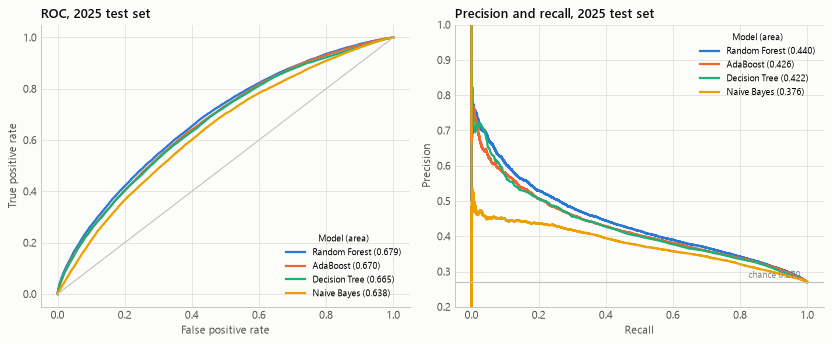

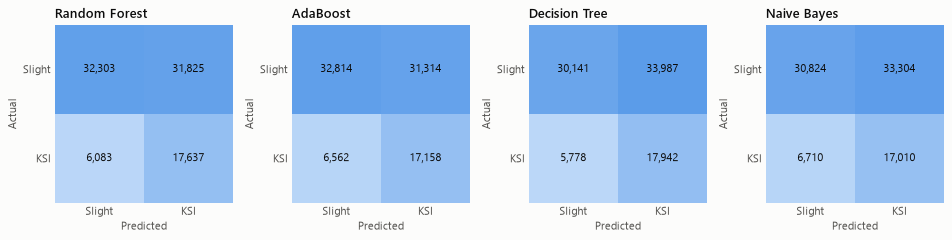

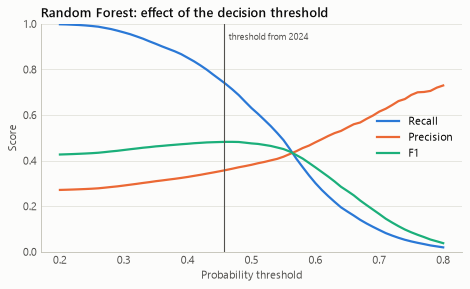

In [17]:
LINE = {"Random Forest": BLUE, "AdaBoost": ORANGE, "Decision Tree": AQUA, "Naive Bayes": YELLOW}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for name in scores["model"]:
    fpr, tpr, _ = roc_curve(y_te, probs[name])
    precision, recall, _ = precision_recall_curve(y_te, probs[name])
    axes[0].plot(fpr, tpr, color=LINE[name], label=f"{name} ({roc_auc_score(y_te, probs[name]):.3f})")
    axes[1].plot(recall, precision, color=LINE[name], label=f"{name} ({average_precision_score(y_te, probs[name]):.3f})")
axes[0].plot([0, 1], [0, 1], color=AXIS, linewidth=1)
axes[0].set(title="ROC, 2025 test set", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_te.mean(), color=AXIS, linewidth=1)
axes[1].text(.98, y_te.mean() + .012, f"chance {y_te.mean():.3f}", color=MUTED, ha="right", fontsize=8.5)
axes[1].set(title="Precision and recall, 2025 test set", xlabel="Recall", ylabel="Precision", ylim=(.2, 1))
for ax in axes:
    ax.grid(True)
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", title="Model (area)", fontsize=8.5, title_fontsize=8.5)
fig.tight_layout()
save(fig, "fig19_severity_roc_pr")

fig, axes = plt.subplots(1, 4, figsize=(12, 2.9))
for ax, row in zip(axes, scores.to_dict("records")):
    cm = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    ax.imshow(cm, cmap=BLUES, vmin=0, vmax=len(y_te))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > len(y_te) * .45 else INK, fontsize=10)
    ax.set_xticks([0, 1], ["Slight", "KSI"])
    ax.set_yticks([0, 1], ["Slight", "KSI"])
    ax.set(title=row["model"], xlabel="Predicted", ylabel="Actual")
    ax.spines[["left", "bottom"]].set_visible(False)
fig.tight_layout()
save(fig, "fig20_confusion_matrices")

prob = probs[BEST]
grid = np.linspace(.2, .8, 61)
curve = pd.DataFrame({"t": grid, "precision": [precision_score(y_te, prob >= t, zero_division=0) for t in grid], "recall": [recall_score(y_te, prob >= t) for t in grid], "f1": [f1_score(y_te, prob >= t) for t in grid]})
fig, ax = plt.subplots(figsize=(6.8, 3.7))
ax.plot(curve["t"], curve["recall"], color=BLUE, label="Recall")
ax.plot(curve["t"], curve["precision"], color=ORANGE, label="Precision")
ax.plot(curve["t"], curve["f1"], color=AQUA, label="F1")
ax.axvline(thresholds[BEST], color=INK2, linewidth=1)
ax.text(thresholds[BEST] + .008, .93, "threshold from 2024", color=INK2, fontsize=8.5)
ax.set(title=f"{BEST}: effect of the decision threshold", xlabel="Probability threshold", ylabel="Score", ylim=(0, 1))
ax.grid(axis="y")
ax.legend(loc="center right")
save(fig, "fig21_threshold")

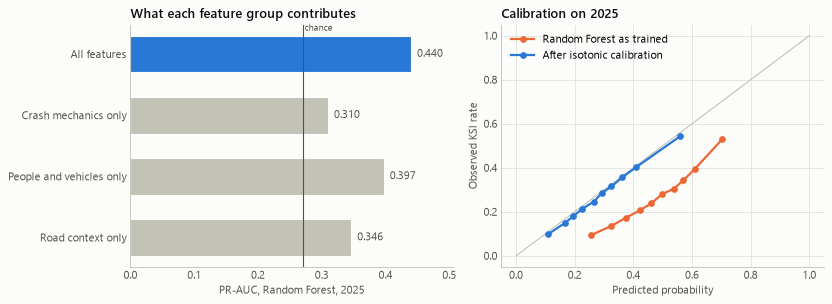

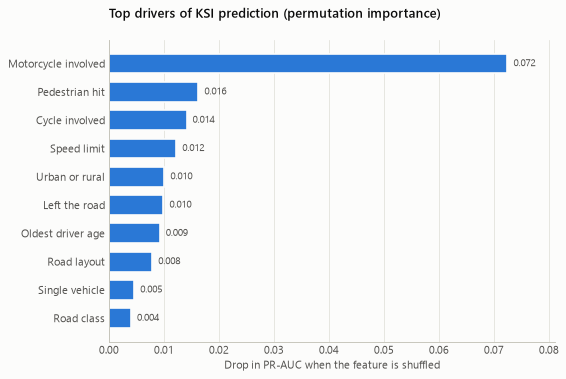

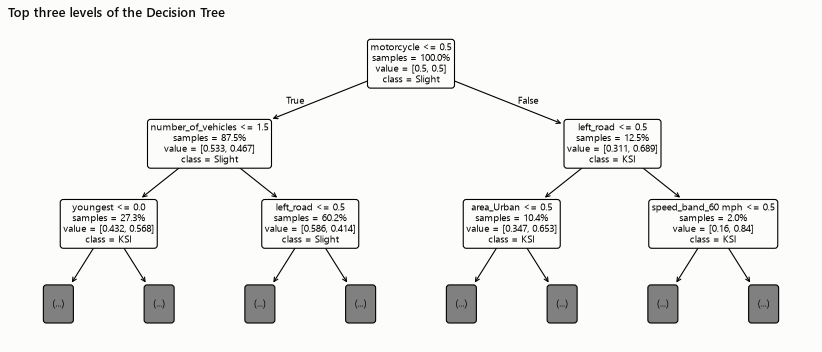

                   features  roc_auc  pr_auc
0         Road context only   0.5910  0.3462
1  People and vehicles only   0.6437  0.3972
2      Crash mechanics only   0.5589  0.3097
3              All features   0.6791  0.4399
0.2238
0.181


In [18]:
abl = []
for label_name, feats in [("Road context only", CONTEXT), ("People and vehicles only", PEOPLE), ("Crash mechanics only", MECHANICS), ("All features", ALL_FEATURES)]:
    pipe = make_pipe(sklearn.base.clone(chosen["Random Forest"]), feats).fit(fit_all[feats], fit_all["ksi"])
    p = pipe.predict_proba(te[feats])[:, 1]
    abl.append({"features": label_name, "roc_auc": round(roc_auc_score(y_te, p), 4), "pr_auc": round(average_precision_score(y_te, p), 4)})
abl = pd.DataFrame(abl)

iso = IsotonicRegression(out_of_bounds="clip").fit(val_prob, va["ksi"])
rf_prob = probs["Random Forest"]
cal_prob = iso.predict(rf_prob)
frac_raw, mean_raw = calibration_curve(y_te, rf_prob, n_bins=10, strategy="quantile")
frac_cal, mean_cal = calibration_curve(y_te, cal_prob, n_bins=10, strategy="quantile")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
pos_y = np.arange(len(abl))
axes[0].barh(abl["features"], abl["pr_auc"], color=[AXIS, AXIS, AXIS, BLUE], height=.6, edgecolor=SURFACE)
for y, v in zip(pos_y, abl["pr_auc"]):
    axes[0].text(v, y, f"  {v:.3f}", va="center", color=INK2)
axes[0].axvline(y_te.mean(), color=INK2, linewidth=1)
axes[0].text(y_te.mean(), len(abl) - .62, " chance", color=INK2, fontsize=8.5)
axes[0].set(title="What each feature group contributes", xlabel="PR-AUC, Random Forest, 2025")
axes[0].margins(x=.15)
axes[1].plot([0, 1], [0, 1], color=AXIS, linewidth=1)
axes[1].plot(mean_raw, frac_raw, color=ORANGE, marker="o", markersize=5, label="Random Forest as trained")
axes[1].plot(mean_cal, frac_cal, color=BLUE, marker="o", markersize=5, label="After isotonic calibration")
axes[1].set(title="Calibration on 2025", xlabel="Predicted probability", ylabel="Observed KSI rate")
axes[1].legend(loc="upper left")
axes[1].grid(True)
fig.tight_layout()
save(fig, "fig22_ablation_calibration")

idx = rng.choice(len(te), 30000, replace=False)
perm = permutation_importance(final["Random Forest"], te.iloc[idx][ALL_FEATURES], y_te[idx], scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=ALL_FEATURES).sort_values(ascending=False)
READ = {"speed_band": "Speed limit", "road_class": "Road class", "road_form": "Road layout", "junction": "Junction type", "crossing": "Crossing facility", "light": "Lighting", "weather": "Weather", "surface": "Road surface", "area": "Urban or rural",
        "hour_band": "Time of day", "day_type": "Weekday or weekend", "pedestrian": "Pedestrian hit", "motorcycle": "Motorcycle involved", "pedal_cycle": "Cycle involved", "hgv": "HGV involved", "bus": "Bus involved", "young_driver": "Driver under 25", "older_driver": "Driver 70 or over", "single_vehicle": "Single vehicle",
        "number_of_vehicles": "Number of vehicles", "youngest": "Youngest driver age", "oldest": "Oldest driver age", "left_road": "Left the road", "skidded": "Skidded", "overturned": "Overturned",
        "hit_fixed_object": "Hit fixed object", "hit_tree_or_pole": "Hit tree or pole", "hit_object_in_road": "Hit object in road"}
fig = hbar(importance.head(10).rename(READ), "Top drivers of KSI prediction (permutation importance)", "Drop in PR-AUC when the feature is shuffled", fmt="{:.3f}")
save(fig, "fig23_severity_importance")

tree = final["Decision Tree"]
names_tree = [n.replace("cat__", "").replace("num__", "") for n in tree["prep"].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(13, 5.2))
plot_tree(tree["model"], max_depth=2, feature_names=names_tree, class_names=["Slight", "KSI"], filled=False, impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Top three levels of the Decision Tree")
save(fig, "fig24_decision_tree")

M["severity"].update({
    "ablation": abl.to_dict("records"), "importance": {READ[k]: round(float(v), 4) for k, v in importance.head(10).items()},
    "brier_raw": round(float(brier_score_loss(y_te, rf_prob)), 4), "brier_calibrated": round(float(brier_score_loss(y_te, cal_prob)), 4),
    "mean_pred_raw": round(float(rf_prob.mean()), 4), "mean_pred_calibrated": round(float(cal_prob.mean()), 4),
    "calibrated_half": {"accuracy": round(float(accuracy_score(y_te, cal_prob >= .5)), 4), "precision": round(float(precision_score(y_te, cal_prob >= .5, zero_division=0)), 4), "recall": round(float(recall_score(y_te, cal_prob >= .5)), 4)},
})
print(abl, M["severity"]["brier_raw"], M["severity"]["brier_calibrated"], sep="\n")

## 7. Next-year location risk (Module III applied to the decision)

Severity at a single collision is partly chance: the same crash can hurt one person badly and another slightly. A safety budget is spent on places, so this section asks a question closer to the decision.

**Question.** Which 500 m cells will record KSI collisions next year?

**Design.** Each cell's features come from three past years. Training uses 2021 to 2023 to predict 2024. The test uses 2022 to 2024 to predict 2025, so nothing from the test year enters its features. Only cells with at least one past collision are scored. KSI totals are severity-adjusted, so forces on different reporting systems are comparable. The baseline is what a traditional black spot list does: rank by past KSI count.

In [19]:
CELL = 500
col["ci"], col["cj"] = (col["e"] // CELL).astype(int), (col["n"] // CELL).astype(int)
col["is_rural"] = (col["area"] == "Rural").astype(int)
col["is_dark"] = (col["light_conditions"] >= 4).astype(int)
col["at_junction"] = col["junction_detail"].isin([13, 16, 17, 18, 19]).astype(int)
col["main_road"] = col["first_road_class"].isin([1, 2, 3]).astype(int)
KEYS = ["ci", "cj"]
OFFSETS = [(a, b) for a in (-1, 0, 1) for b in (-1, 0, 1) if (a, b) != (0, 0)]


def cell_frame(history, target=None):
    h = col[col["collision_year"].isin(history)]
    f = h.groupby(KEYS).agg(collisions=("ksi_adj", "size"), ksi=("ksi_adj", "sum"), fatal=("fatal", "sum"), speed=("speed_limit", "mean"), rural=("is_rural", "mean"), junction=("at_junction", "mean"),
                            dark=("is_dark", "mean"), main_road=("main_road", "mean"), pedestrian=("pedestrian", "mean"), motorcycle=("motorcycle", "mean"), pedal_cycle=("pedal_cycle", "mean"),
                            vehicles=("number_of_vehicles", "mean"), years_active=("collision_year", "nunique"))
    last = h[h["collision_year"] == max(history)].groupby(KEYS).agg(collisions_last=("ksi_adj", "size"), ksi_last=("ksi_adj", "sum"))
    f = f.join(last).fillna(0)
    base_counts = f[["collisions", "ksi"]].reset_index()
    around = pd.concat([base_counts.assign(ci=base_counts["ci"] + a, cj=base_counts["cj"] + b) for a, b in OFFSETS]).groupby(KEYS).sum()
    f = f.join(around.rename(columns={"collisions": "near_collisions", "ksi": "near_ksi"})).fillna(0)
    y = None
    if target is not None:
        y = col[col["collision_year"] == target].groupby(KEYS)["ksi_adj"].sum().reindex(f.index).fillna(0)
    return f, y


X_tr, y_tr = cell_frame([2021, 2022, 2023], 2024)
X_te, y_te_cell = cell_frame([2022, 2023, 2024], 2025)
total_2025 = float(col.loc[col["collision_year"] == 2025, "ksi_adj"].sum())
pos_te = (y_te_cell >= .5).to_numpy()

LOC = {
    "Decision Tree": DecisionTreeClassifier(max_depth=7, min_samples_leaf=100, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=14, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "AdaBoost": AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=200, learning_rate=.3, random_state=SEED),
}
loc_scores = {"Past KSI count (baseline)": (X_te["ksi"] + 1e-4 * X_te["collisions"]).to_numpy()}
loc_models = {}
for name, model in LOC.items():
    loc_models[name] = model.fit(X_tr, y_tr >= .5)
    loc_scores[name] = model.predict_proba(X_te)[:, 1]
loc_models["Poisson boosting"] = HistGradientBoostingRegressor(loss="poisson", max_iter=250, learning_rate=.05, max_leaf_nodes=31, random_state=SEED).fit(X_tr, y_tr)
loc_scores["Poisson boosting"] = loc_models["Poisson boosting"].predict(X_te)


def capture(score, k, y=None):
    y = y_te_cell.to_numpy() if y is None else y
    return float(y[np.argsort(-score)[:k]].sum() / total_2025 * 100)


SITES = [100, 500, 1000, 5000, 10000]
loc_rows = []
for name, s in loc_scores.items():
    row = {"model": name, "roc_auc": roc_auc_score(pos_te, s), "pr_auc": average_precision_score(pos_te, s)}
    row.update({f"top_{k}": capture(s, k) for k in SITES})
    loc_rows.append(row)
loc_table = pd.DataFrame(loc_rows).sort_values("top_5000", ascending=False)
loc_table.to_csv(RES / "location_scores.csv", index=False)
LOC_BEST = loc_table[loc_table["model"] != "Past KSI count (baseline)"].iloc[0]["model"]

y_arr = y_te_cell.to_numpy()
diff = []
for _ in range(200):
    i = rng.integers(0, len(y_arr), len(y_arr))
    a = np.argsort(-loc_scores[LOC_BEST][i])[:5000]
    b = np.argsort(-loc_scores["Past KSI count (baseline)"][i])[:5000]
    diff.append((y_arr[i][a].sum() - y_arr[i][b].sum()) / total_2025 * 100)

# a known trap: sites picked on one bad year look better afterwards with no treatment at all
worst = X_te.sort_values("ksi_last", ascending=False).head(100)
rtm_before = float(worst["ksi_last"].mean())
rtm_after = float(y_te_cell.loc[worst.index].mean())

M["location"] = {
    "cell_m": CELL, "train_cells": len(X_tr), "test_cells": len(X_te), "positive_pct": round(float(pos_te.mean()) * 100, 2), "best": LOC_BEST, "total_2025_adj_ksi": round(total_2025),
    "scored_share_pct": round(float(y_arr.sum() / total_2025) * 100, 2), "table": loc_table.round(4).to_dict("records"), "gain_top5000": round(float(np.mean(diff)), 2),
    "gain_ci": [round(float(np.percentile(diff, q)), 2) for q in (2.5, 97.5)], "rtm_before": round(rtm_before, 2), "rtm_after": round(rtm_after, 2), "rtm_drop_pct": round((1 - rtm_after / rtm_before) * 100, 1),
    "features": list(X_tr.columns),
}
print({k: v for k, v in M["location"].items() if k not in ("table", "features")})
loc_table.round(3)

{'cell_m': 500, 'train_cells': 95022, 'test_cells': 95806, 'positive_pct': 16.42, 'best': 'Poisson boosting', 'total_2025_adj_ksi': 27195, 'scored_share_pct': 78.98, 'gain_top5000': 2.13, 'gain_ci': [1.78, 2.53], 'rtm_before': 6.4, 'rtm_after': 3.85, 'rtm_drop_pct': 39.8}


,model,roc_auc,pr_auc,top_100,top_500,top_1000,top_5000,top_10000
4,Poisson boosting,0.764,0.460,1.752,5.787,9.290,24.146,34.349
2,Random Forest,0.761,0.456,1.611,5.718,9.130,24.023,33.926
3,AdaBoost,0.762,0.455,1.797,5.746,9.104,23.658,34.006
1,Decision Tree,0.759,0.442,1.324,5.667,8.944,23.523,33.717
0,Past KSI count (baseline),0.680,0.381,1.797,5.391,8.613,22.034,31.162


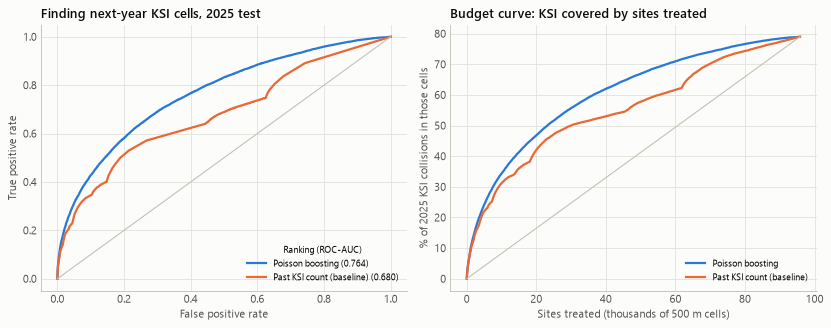

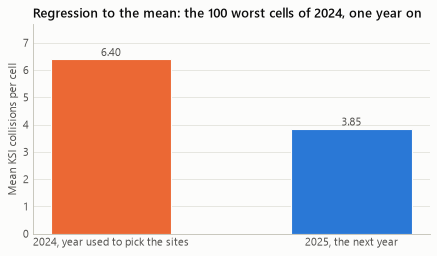

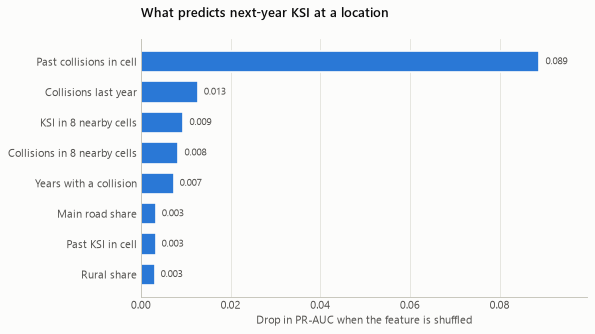

In [20]:
base_key = "Past KSI count (baseline)"
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for name, color in [(LOC_BEST, BLUE), (base_key, ORANGE)]:
    fpr, tpr, _ = roc_curve(pos_te, loc_scores[name])
    axes[0].plot(fpr, tpr, color=color, label=f"{name} ({roc_auc_score(pos_te, loc_scores[name]):.3f})")
    ranked = np.cumsum(y_arr[np.argsort(-loc_scores[name])]) / total_2025 * 100
    x = np.arange(1, len(ranked) + 1)
    axes[1].plot(x / 1000, ranked, color=color, label=name)
axes[0].plot([0, 1], [0, 1], color=AXIS, linewidth=1)
axes[0].set(title="Finding next-year KSI cells, 2025 test", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(loc="lower right", title="Ranking (ROC-AUC)", fontsize=8.5, title_fontsize=8.5)
axes[1].plot([0, len(y_arr) / 1000], [0, y_arr.sum() / total_2025 * 100], color=AXIS, linewidth=1)
axes[1].set(title="Budget curve: KSI covered by sites treated", xlabel="Sites treated (thousands of 500 m cells)", ylabel="% of 2025 KSI collisions in those cells")
axes[1].legend(loc="lower right", fontsize=8.5)
for ax in axes:
    ax.grid(True)
fig.tight_layout()
save(fig, "fig25_location_model")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(["2024, year used to pick the sites", "2025, the next year"], [rtm_before, rtm_after], color=[ORANGE, BLUE], width=.5, edgecolor=SURFACE)
for x, v in enumerate([rtm_before, rtm_after]):
    ax.text(x, v, f"{v:.2f}\n", ha="center", va="center", color=INK2)
ax.set(title="Regression to the mean: the 100 worst cells of 2024, one year on", ylabel="Mean KSI collisions per cell", ylim=(0, rtm_before * 1.2))
ax.grid(axis="y")
ax.set_axisbelow(True)
save(fig, "fig26_regression_to_mean")

rf_imp = pd.Series(loc_models["Random Forest"].feature_importances_, index=X_tr.columns).sort_values(ascending=False)
perm_loc = permutation_importance(loc_models["Random Forest"], X_te, pos_te, scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=1)
loc_importance = pd.Series(perm_loc.importances_mean, index=X_tr.columns).sort_values(ascending=False)
LOC_READ = {"collisions": "Past collisions in cell", "ksi": "Past KSI in cell", "fatal": "Past fatal in cell", "speed": "Mean speed limit", "rural": "Rural share", "junction": "Junction share", "dark": "Darkness share", "main_road": "Main road share", "pedestrian": "Pedestrian share",
            "motorcycle": "Motorcycle share", "pedal_cycle": "Cycle share", "vehicles": "Vehicles per collision", "years_active": "Years with a collision", "collisions_last": "Collisions last year", "ksi_last": "KSI last year", "near_collisions": "Collisions in 8 nearby cells", "near_ksi": "KSI in 8 nearby cells"}
fig = hbar(loc_importance.head(8).rename(LOC_READ), "What predicts next-year KSI at a location", "Drop in PR-AUC when the feature is shuffled", fmt="{:.3f}")
save(fig, "fig27_location_importance")
M["location"]["importance"] = {LOC_READ[k]: round(float(v), 4) for k, v in loc_importance.head(8).items()}

## 8. Decision: the 2026 priority list

The chosen model is refit on the latest full window (2022 to 2024 predicting 2025) and scores cells on 2023 to 2025, giving a forward-looking list for 2026. Each site gets a suggested review type taken from its own collision mix. That suggestion is a starting point for an engineer, not a model output, and it does not claim a crash reduction.

{'top10': [{'rank': 1, 'authority': 'City of London', 'road': 'A3', 'ksi': 23.0, 'collisions': 73, 'pattern': 'Cycle', 'review': 'Cycle separation and junction protection review'}, {'rank': 2, 'authority': 'City of London', 'road': 'A201', 'ksi': 28.0, 'collisions': 71, 'pattern': 'Cycle', 'review': 'Cycle separation and junction protection review'}, {'rank': 3, 'authority': 'Southwark', 'road': 'A201', 'ksi': 19.0, 'collisions': 83, 'pattern': 'Cycle', 'review': 'Cycle separation and junction protection review'}, {'rank': 4, 'authority': 'Southwark', 'road': 'A3', 'ksi': 19.0, 'collisions': 77, 'pattern': 'Cycle', 'review': 'Cycle separation and junction protection review'}, {'rank': 5, 'authority': 'Westminster', 'road': 'A401', 'ksi': 35.0, 'collisions': 150, 'pattern': 'Pedestrian', 'review': 'Pedestrian crossing and speed review'}, {'rank': 6, 'authority': 'Westminster', 'road': 'A40', 'ksi': 21.0, 'collisions': 89, 'pattern': 'Cycle', 'review': 'Cycle separation and junction prot

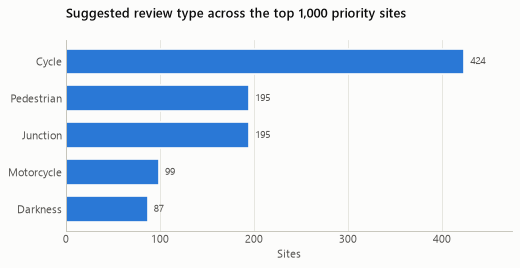

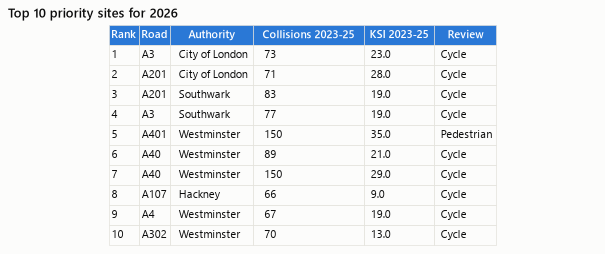

In [21]:
X_now, _ = cell_frame([2023, 2024, 2025])
refit = sklearn.base.clone(loc_models[LOC_BEST])
target = (y_te_cell >= .5) if LOC_BEST != "Poisson boosting" else y_te_cell
refit.fit(X_te, target)
score_now = refit.predict(X_now) if LOC_BEST == "Poisson boosting" else refit.predict_proba(X_now)[:, 1]
priority = X_now.assign(score=score_now).sort_values("score", ascending=False).head(1000)

recent = col[col["collision_year"].isin([2023, 2024, 2025])]
info = recent.groupby(KEYS).agg(lat=("latitude", "mean"), lon=("longitude", "mean"), authority=("authority", lambda s: s.mode().iat[0]), road=("road_name", named_road))
priority = priority.join(info)
priority["high_speed"] = (priority["speed"] >= 50).astype(float)
priority["at_junction"] = priority["junction"]
priority["pattern"] = priority.rename(columns={}).apply(lambda r: dominant({"pedestrian": r["pedestrian"], "motorcycle": r["motorcycle"], "pedal_cycle": r["pedal_cycle"], "dark": r["dark"], "at_junction": r["at_junction"], "high_speed": r["high_speed"]}), axis=1)
priority["review"] = priority["pattern"].map(REVIEW)
priority["pattern"] = priority["pattern"].map(PATTERN)
priority["rank"] = range(1, len(priority) + 1)
priority[["rank", "authority", "road", "lat", "lon", "score", "collisions", "ksi", "fatal", "pattern", "review"]].round(3).to_csv(RES / "priority_sites_2026.csv")

hub = NearestNeighbors(radius=750).fit(hs[["e", "n"]].to_numpy())
centre = np.c_[(priority.index.get_level_values("ci") + .5) * CELL, (priority.index.get_level_values("cj") + .5) * CELL]
overlap = np.mean([len(x) > 0 for x in hub.radius_neighbors(centre[:100], return_distance=False)]) * 100

M["decision"] = {
    "top10": [{"rank": int(r["rank"]), "authority": r["authority"], "road": r["road"], "ksi": round(float(r["ksi"]), 1), "collisions": int(r["collisions"]), "pattern": r["pattern"], "review": r["review"]} for _, r in priority.head(10).iterrows()],
    "pattern_top100": {k: int(v) for k, v in priority.head(100)["pattern"].value_counts().items()},
    "pattern_top1000": {k: int(v) for k, v in priority["pattern"].value_counts().items()},
    "top100_near_hotspot_pct": round(float(overlap), 1),
    "authorities_top100": {k: int(v) for k, v in priority.head(100)["authority"].value_counts().head(8).items()},
}
print(M["decision"])

fig = hbar(priority.head(1000)["pattern"].value_counts().astype(float), "Suggested review type across the top 1,000 priority sites", "Sites", fmt="{:.0f}")
save(fig, "fig28_review_mix")

show = priority.head(10).copy()
show = show[["rank", "road", "authority", "collisions", "ksi", "pattern"]]
show["ksi"] = show["ksi"].round(1)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.axis("off")
table = ax.table(cellText=show.astype(str).values, colLabels=["Rank", "Road", "Authority", "Collisions 2023-25", "KSI 2023-25", "Review"], loc="center", cellLoc="left")
table.auto_set_font_size(False)
table.set_fontsize(9.5)
table.scale(1, 1.5)
for (i, j), cell in table.get_celld().items():
    cell.set_edgecolor(GRID)
    cell.set_linewidth(.6)
    cell.set_text_props(color=INK if i else "white", fontweight="semibold" if i == 0 else "normal")
    cell.set_facecolor(BLUE if i == 0 else SURFACE)
table.auto_set_column_width(range(6))
ax.set_title("Top 10 priority sites for 2026")
save(fig, "fig29_priority_table")

In [22]:
lat0, lon0 = 53.5, -2.5
site_map = folium.Map(location=[lat0, lon0], zoom_start=6, tiles="CartoDB positron")
layer_h = folium.FeatureGroup(name=f"Hotspots, top 300 of {len(hs)}", show=True)
for _, r in hs.head(300).iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius=3 + r["ksi_collisions"] ** .5 / 1.5, color=ORANGE, weight=1, fill=True, fill_opacity=.55,
                        popup=f"<b>Hotspot #{int(r['rank'])}</b><br>{r['road']}, {r['authority']}<br>KSI collisions 2021-25: {int(r['ksi_collisions'])}<br>Fatal: {int(r['fatal'])}<br>Span: {int(r['span_m'])} m<br>Review: {r['review']}").add_to(layer_h)
layer_p = folium.FeatureGroup(name="Priority sites for 2026, top 100", show=True)
for _, r in priority.head(100).iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius=5, color=BLUE, weight=1, fill=True, fill_opacity=.75,
                        popup=f"<b>Priority #{int(r['rank'])}</b><br>{r['road']}, {r['authority']}<br>Collisions 2023-25: {int(r['collisions'])}<br>KSI 2023-25: {r['ksi']:.1f}<br>Review: {r['review']}").add_to(layer_p)
layer_h.add_to(site_map)
layer_p.add_to(site_map)
folium.LayerControl(collapsed=False).add_to(site_map)
site_map.save(ROOT / "blackspot_map.html")

M["runtime_minutes"] = round((time.time() - T0) / 60, 1)
(RES / "metrics.json").write_text(json.dumps(M, indent=2, default=str), encoding="utf-8")
print("saved", RES / "metrics.json", "in", M["runtime_minutes"], "minutes")

C:\Users\ANEXUS\Desktop\DMBI-CAs-D15A-Gr09\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


saved C:\Users\ANEXUS\Desktop\DMBI-CAs-D15A-Gr09\DMBI CAs 54,52,53,49\CA2\results\metrics.json in 21.6 minutes


## 9. Findings and limits

All values are in `results/metrics.json`, and the report and slides read from that file.

**Limits that apply to every result above.**

- STATS19 holds police-reported injury collisions only. Damage-only crashes are absent and some injury crashes go unreported.
- There is no traffic-volume data, so a busy site scores high partly because it is busy. A rate per vehicle would need flow counts.
- The model finds association, not cause. A rule does not prove that changing a condition would prevent a crash.
- Location scores cover cells with a past collision. A site with no history cannot be ranked.
- Severity adjustment is a statistical estimate from DfT, not an observed value.
- The data is from Great Britain. The method transfers to India through eDAR/iRAD, but these numbers do not.